<a href="https://colab.research.google.com/github/RobertoSonzini/NAML_project/blob/main/Progetto_NAML_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Progetto NAML**

***10794845 - Roberto Sonzini Gobbi***

***10811227 - Fabio Marco Floris***

GitHub link:
https://github.com/RobertoSonzini/NAML_project/tree/main

## **Project Overview**

In recent years, deep learning techniques have demonstrated remarkable success in a wide range of fields, including financial forecasting.

Our project takes inspiration from the work of *Zhang et al. (2019), “Stock Market Prediction Based on Generative Adversarial Network”*, in which the authors propose a novel Generative Adversarial Network (GAN) architecture tailored for stock price forecasting. Their framework combines a **Long Short-Term Memory (LSTM)** network, acting as the **generator**, with a **Multi-Layer Perceptron (MLP)**, acting as the **discriminator**. The **LSTM** is particularly well-suited for handling sequential data, as it can capture temporal dependencies in stock prices, while the **MLP** effectively distinguishes between real and generated data distributions.

Building on this foundation, our work seeks to reproduce and adapt similar ideas, with the aim of exploring the potential of GAN-based architectures for predicting the daily closing price of stocks. In addition to implementing this adversarial approach, we also conducted a comparative analysis with more classical models, including a standalone **LSTM**, a standard Artificial Neural Network (**ANN**), and a regression Support Vector Machine (**SVR**). This comparison allows us to better evaluate the advantages and limitations of the GAN-based strategy in relation to widely used machine learning techniques.

## **Imports**

In [1]:
!pip uninstall torch
!pip cache purge
!pip install torch --upgrade

Found existing installation: torch 2.8.0+cu126
Uninstalling torch-2.8.0+cu126:
  Would remove:
    /usr/local/bin/torchfrtrace
    /usr/local/bin/torchrun
    /usr/local/lib/python3.12/dist-packages/functorch/*
    /usr/local/lib/python3.12/dist-packages/torch-2.8.0+cu126.dist-info/*
    /usr/local/lib/python3.12/dist-packages/torch/*
    /usr/local/lib/python3.12/dist-packages/torchgen/*
Proceed (Y/n)? Y
  Successfully uninstalled torch-2.8.0+cu126
Files removed: 0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.9/887.9 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 87.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
from sklearn.utils import shuffle

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

import jax
import jax.numpy as jnp
import jax.scipy.optimize
from jax import grad, jit, vmap, lax, random
from jax.nn import sigmoid

import math
from datetime import datetime

plt.rcParams['lines.linewidth'] = 2

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## **Dataset study**

Here we mount **Google Drive** to access the dataset, load the **CSV file** containing stock data into a **Pandas DataFrame**, and display basic information about its structure and contents.

As we can observe from the output of the following code, the dataset contains 619,040 entries and 7 columns, which include the **date, stock prices (open, high, low, close), trading volume, and the company name**. Most columns are complete, with only a few missing values in the price-related fields. The dataset occupies about 33 MB of memory.

Moreover, this dataset appears suitable for reproducing the work described in the paper, as it provides several of the required features **(high, low, open, close, and volume)** which align with those mentioned in the paper **(high, low, open, close, turnover_rate, volume, and MA5)**.

Unfortunately, the **turnover_rate** parameter is not available in this dataset, but the **MA5** (5-day moving average) can be computed and therefore will be added to our data.

In [4]:
file_path = '/content/drive/MyDrive/ProgettoNAML/all_stocks_5yr.csv'
drive.mount('/content/drive')

df = pd.read_csv(file_path)
df.head()

%matplotlib inline

df.info()
df

Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL
...,...,...,...,...,...,...,...
619035,2018-02-01,76.84,78.27,76.69,77.82,2982259,ZTS
619036,2018-02-02,77.53,78.12,76.73,76.78,2595187,ZTS
619037,2018-02-05,76.64,76.92,73.18,73.83,2962031,ZTS
619038,2018-02-06,72.74,74.56,72.13,73.27,4924323,ZTS


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


In [6]:
latest_date = pd.to_datetime(df['date']).max()

one_year_before = latest_date - pd.DateOffset(years=1)

date_series = pd.to_datetime(df['date'])
mask = (date_series >= one_year_before) & (date_series <= latest_date) & (df['Name'] == 'AAPL')

filtered_df = df[mask]
filtered_df['date'] = pd.to_datetime(filtered_df['date'])

/tmp/ipython-input-1817002058.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['date'] = pd.to_datetime(filtered_df['date'])


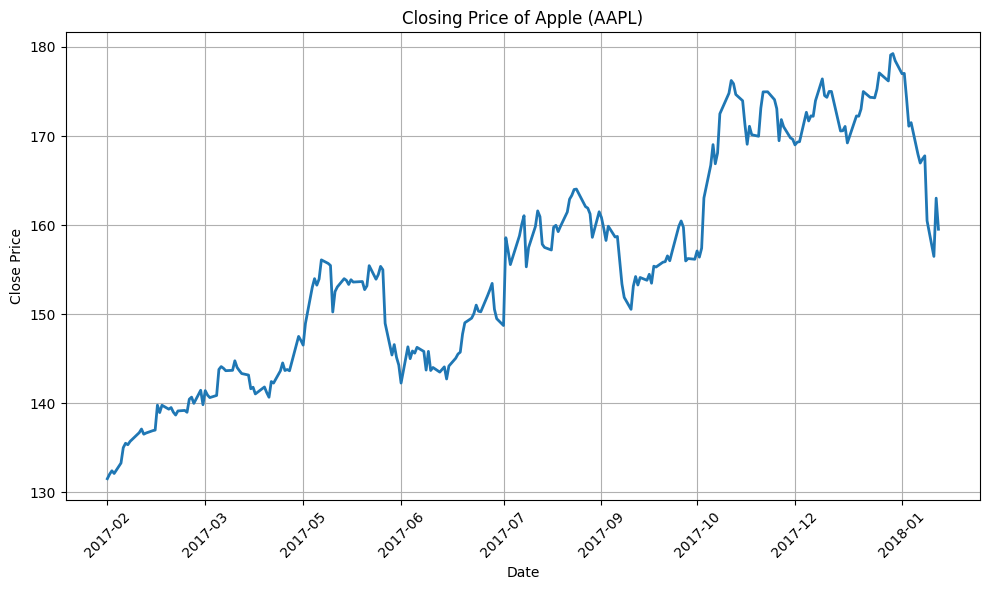

In [7]:
plt.figure(figsize=(10,6))
plt.plot(filtered_df['date'], filtered_df['close'])
plt.ylabel('Close Price')
plt.xlabel('Date')
plt.title("Closing Price of Apple (AAPL)")

step = 30

plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

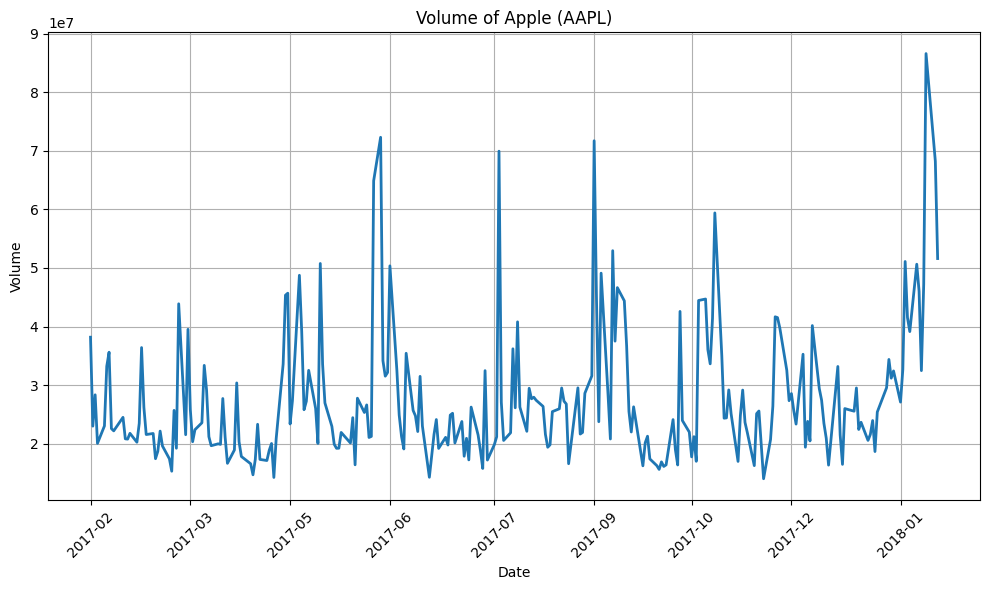

In [8]:
plt.figure(figsize=(10,6))
plt.plot(filtered_df['date'], filtered_df['volume'])
plt.ylabel('Volume')
plt.xlabel('Date')
plt.title("Volume of Apple (AAPL)")

step = 30

plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

In our dataset, one of the features is the trading **volume** of a given company. Since trading volume can be highly variable and often includes extreme values, it is particularly prone to **outliers**. To mitigate this issue, we later apply a logarithmic transformation to obtain the **log-volume**. This approach helps normalize the distribution, reduce skewness, and improve the stability of the feature, making it more suitable for predictive modeling.

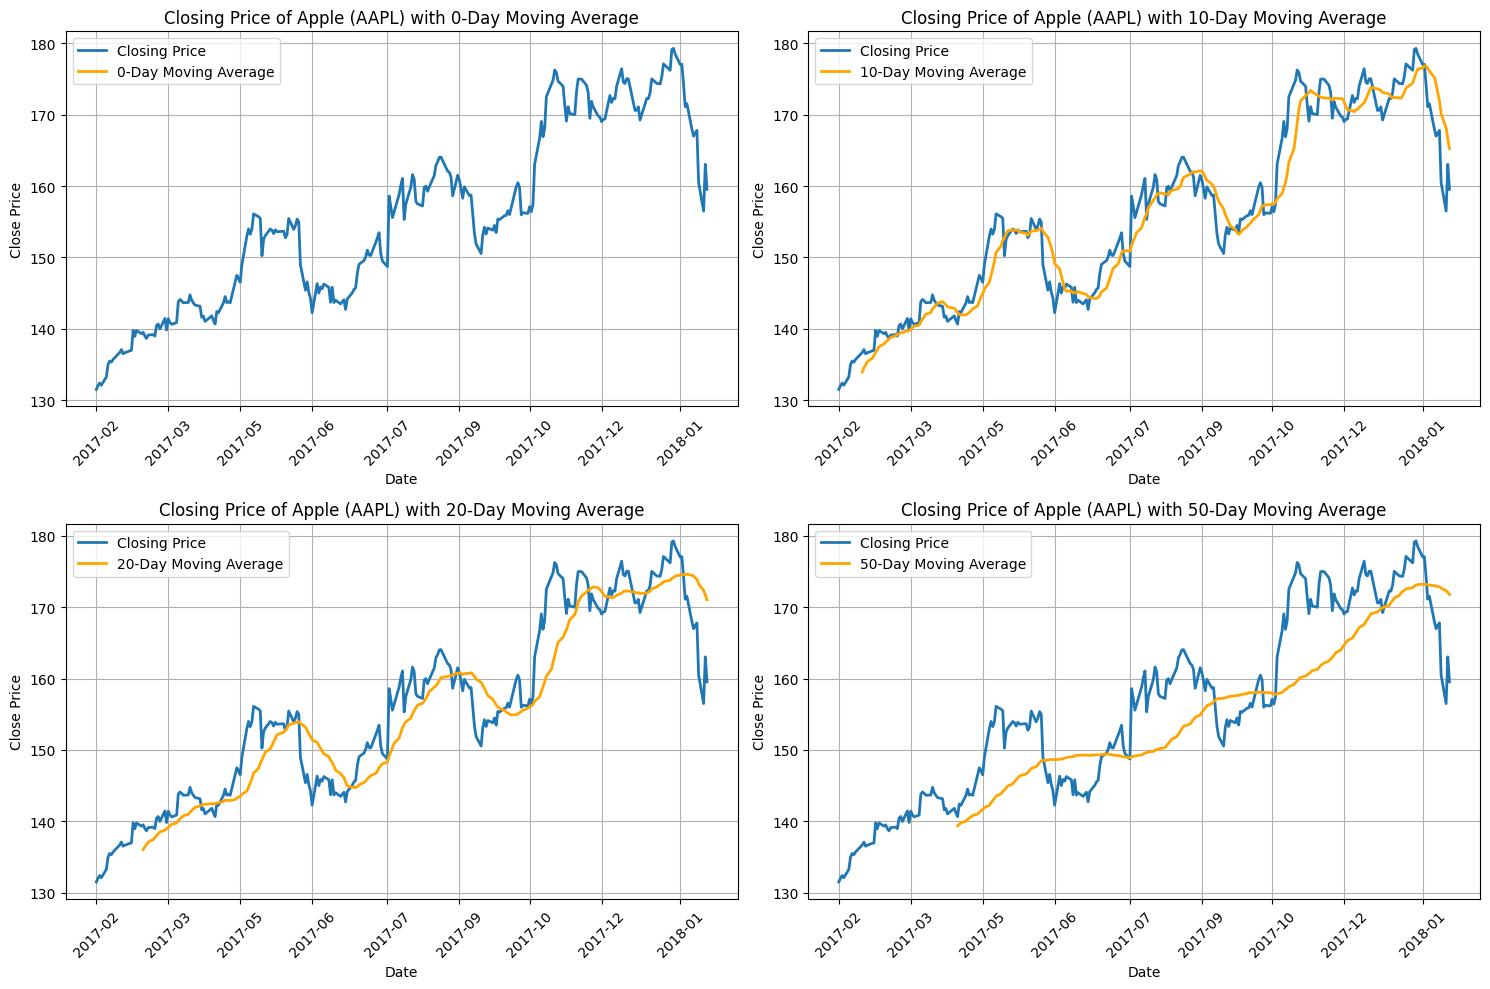

In [9]:
ma_day = [0, 10, 20, 50]
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))

for i, ma in enumerate(ma_day):
    df_copy = filtered_df.copy()
    df_copy['ma_close'] = df_copy['close'].rolling(ma).mean()

    ax = axes[i // 2, i % 2]

    ax.plot(df_copy['date'], df_copy['close'], label='Closing Price')

    ax.plot(df_copy['date'], df_copy['ma_close'], label=f'{ma}-Day Moving Average', color='orange')

    ax.set_ylabel('Close Price')
    ax.set_xlabel('Date')
    ax.set_title(f"Closing Price of Apple (AAPL) with {ma}-Day Moving Average")
    ax.legend()

    step = 30
    ax.set_xticks(df_copy['date'][::step])
    ax.set_xticklabels(df_copy['date'].dt.strftime('%Y-%m')[::step], rotation=45)

    ax.grid(True)

plt.tight_layout()
plt.show()

## **Dataset setup**

In [10]:
df.head()

,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


### **Complete the dataset**

After importing and analyzing the dataset, we conducted a **correlation study** and observed that several features were highly correlated with the **target variable**, in some cases with correlation values approaching 1. This is because, in the original dataset, the target variable at time *t* corresponds to the closing price at the same time, making it **directly dependent** on other data from that day.

From a **predictive perspective**, we therefore shifted the closing price (target) column so that, at each time *t*, it represented the closing price at time *t+1*. Given the relatively **low** day-to-day **variability**, this adjustment still resulted in a very high correlation between the input features and the target.

Although this could lead to very high predictive accuracy, it would not have provided **meaningful insights**, as the model would effectively learn trivial linear relationships. To address this, we modified the dataset to ensure that the relationship between the features and the target was not purely linear, allowing the model to capture more **informative and robust patterns**.

With the following code, we filter the original dataset to include data from a single company. At the same time, we complete the dataset by adding the missing fields required for our analysis.

In [11]:
def sort_by_date(df):
  return df.sort_values(by='date')

In [12]:
def get_dataframe_full(df, company_names, moving_average=5):
    input_data_labels = ['high', 'low', 'open', 'volume', 'close', 'ma5']
    close_data = ['close']

    mask = df['Name'].isin(company_names)
    df_company = df.loc[mask].copy()

    df_company['ma5'] = df_company['close'].rolling(moving_average).mean()

    df_company = df_company.dropna()

    df_company = sort_by_date(df_company)

    return df_company[input_data_labels]

In [13]:
def prepare_dataset_for_forecast(df, company_names, moving_average=5, shift = 1):
    df_company = get_dataframe_full(df, company_names, moving_average)

    df_company['return'] = df_company['close'].pct_change()
    df_company['high_low'] = df_company['high'] - df_company['low']
    df_company['close_open'] = df_company['close'] - df_company['open']
    df_company['log_volume'] = np.log(df_company['volume'] + 1)
    df_company[f'ma{moving_average}'] = df_company['close'].rolling(moving_average).mean()

    df_company['target_close'] = df_company['close'].shift(-shift)

    df_company = df_company.drop(columns=['close'])

    df_company = df_company.rename(columns={'target_close': 'close'})

    df_company = df_company.dropna()

    return df_company

In [14]:
def get_dataframe(df, company_names, moving_average=5):
    df_forecasting = prepare_dataset_for_forecast(df, company_names, moving_average)
    input_data_labels = ['return', 'high_low', 'close_open', 'log_volume', f'ma{moving_average}']

    close_data = ['close']
    return df_forecasting[input_data_labels], df_forecasting[close_data]

In [15]:
def get_dataframe_mod(df, company_names, moving_average=5, shift = 1):
    df_forecasting = prepare_dataset_for_forecast(df, company_names, moving_average, shift)
    input_data_labels = ['return', 'high_low', 'close_open', 'log_volume', f'ma{moving_average}', 'close']

    close_data = ['close']
    return df_forecasting[input_data_labels], df_forecasting[close_data]

In [16]:
df_apple, apple_closings = get_dataframe(df, ['AAPL'])
df_apple.head()

,return,high_low,close_open,log_volume,ma5
1267,-0.006216,0.9072,0.0086,18.530403,65.18994
1268,0.010649,0.7143,0.2229,18.229324,64.73910
1269,-0.017768,1.7929,-1.5785,18.347030,64.24310
1270,0.013934,1.9828,0.7357,18.644597,63.92824
1271,-0.009801,1.6843,-0.5515,18.803728,63.80594


In [17]:
df_apple.shape[0]

1250

### **Correlation**

In [18]:
def plot_correlations(df, method='pearson'):
    corr = df.corr(method=method)

    plt.figure(figsize=(8,6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title(f"Correlation heatmap ({method})", fontsize=14)
    plt.show()

    corr_with_close = corr['close'].drop('close').sort_values(ascending=False)
    print("Correlation with 'close':\n")
    print(corr_with_close)

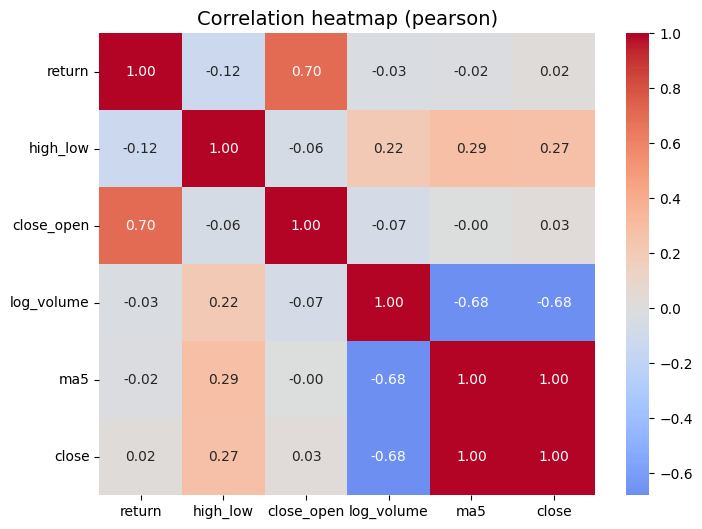

Correlation with 'close':

ma5           0.997075
high_low      0.273312
close_open    0.025725
return        0.019270
log_volume   -0.679887
Name: close, dtype: float64


In [19]:
df_company_full, _ = get_dataframe_mod(df, ['AAPL'])
plot_correlations(df_company_full, method='pearson')

The following analysis studies **how explanatory variables** (such as ma5, high_low, close_open, return, log_volume) **correlate with the future value of the target** (close) as the time shift varies. For each lag (t+1, t+2, ...), the linear correlation between the features observed at time t and the price at time t+lag is calculated. In this way, it is possible to understand to what extent the **information contained** in the variables retains **predictive power** in the future. This approach provides useful information for selecting the sequence length in sequential models such as LSTMs and helps to identify which features maintain a significant relationship with the target over different time horizons, avoiding both sequences that are too short, which would lose information, and sequences that are too long, which would introduce noise.

In [20]:
def plot_correlations_with_close(df, method='pearson'):
    corr = df.corr(method=method)
    corr_with_close = corr['close'].drop('close').sort_values(ascending=False)
    return corr_with_close

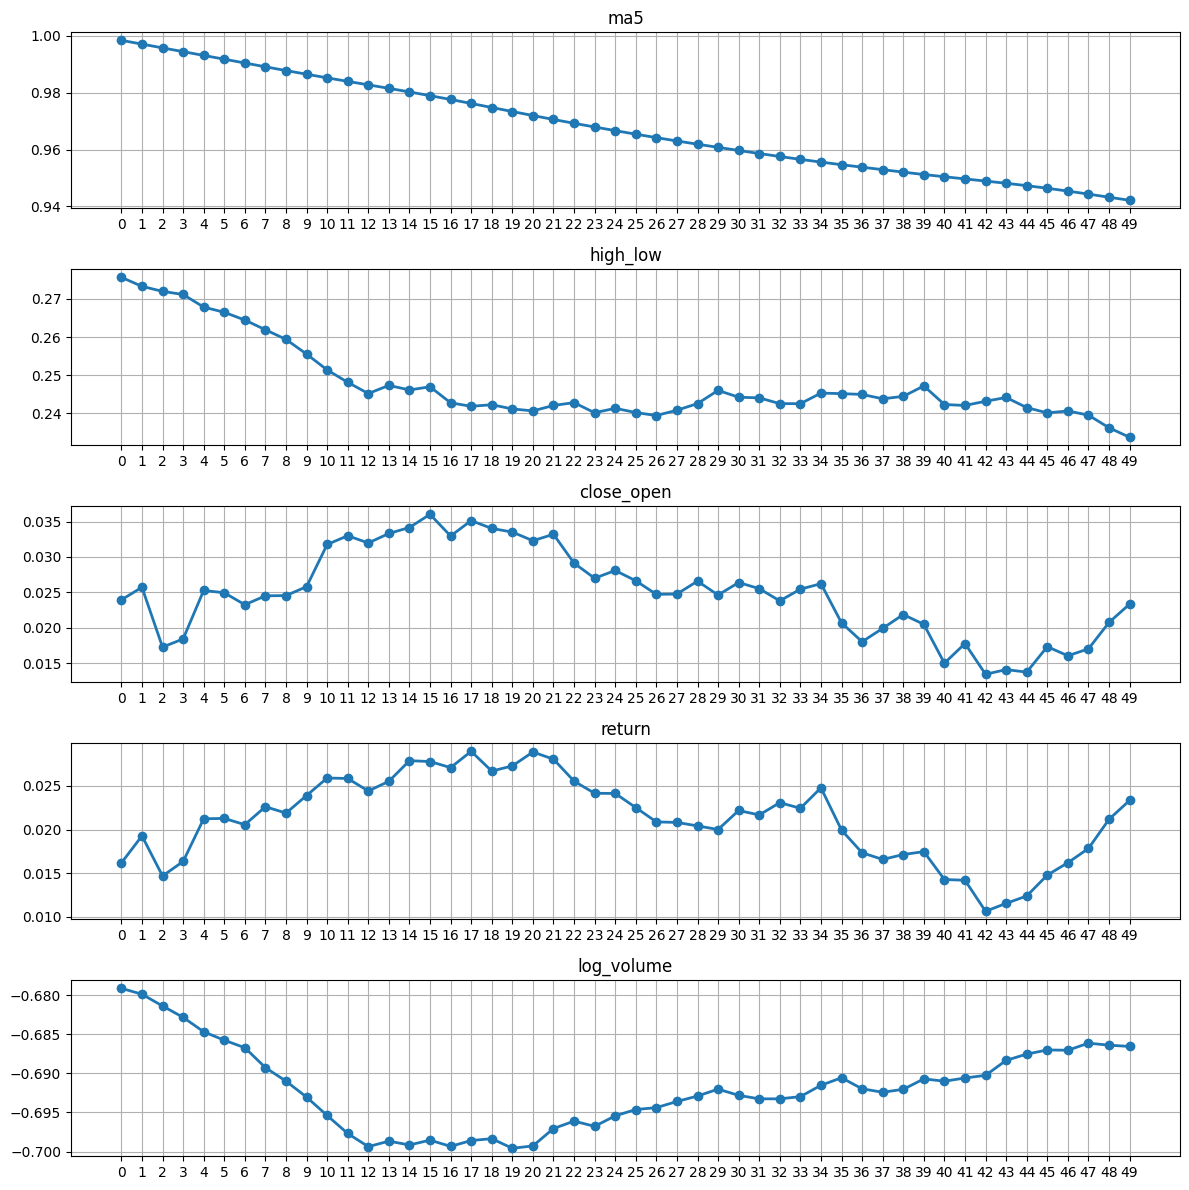

In [21]:
corr_matrix = {}
for i in range(0, 50):
  df_company_correlation, _ = get_dataframe_mod(df, ['AAPL'], shift = i)
  corr_with_close = plot_correlations_with_close(df_company_correlation, method='pearson')
  corr_matrix[i] = corr_with_close

df_corr = pd.DataFrame.from_dict(corr_matrix, orient="index")
fig, axs = plt.subplots(5, 1, figsize=(12, 12), sharex=False)

cols = ["ma5", "high_low", "close_open", "return", "log_volume"]

for i, col in enumerate(cols):
    axs[i].plot(df_corr.index, df_corr[col], marker="o")
    axs[i].set_title(col)
    axs[i].grid(True)
    axs[i].set_xticks(df_corr.index)
    axs[i].set_xticklabels(df_corr.index)


plt.tight_layout()
plt.show()

Analyzing the graphs obtained, the most relevant features lose their predictive power after about 10 time steps. This can give us a clue about the sequence length to use in LSTM models.

# **Networks**

## **ANN**

Here we implement a simple **ANN** using the PyTorch framework.

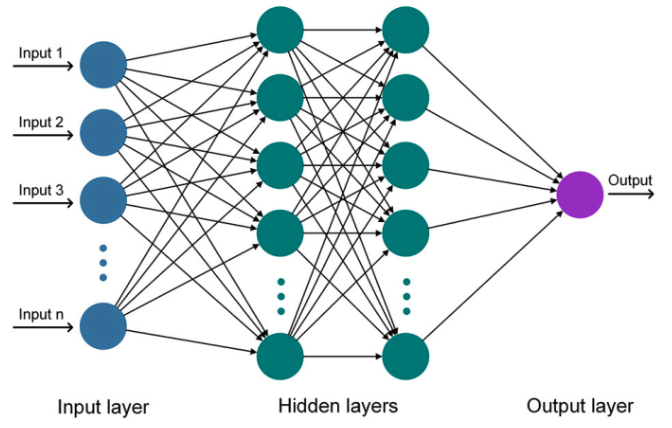

### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [33]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ["AAPL"])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

This class defines a custom PyTorch dataset for sequence data.
This class will be used to create a **data loader** that provides the inputs as **(batch_size, input_size)** and the labels as **(batch_size, number of target features)**. This structure is necessary because, in this implementation, we use PyTorch libraries that require data to have these shapes.

In [34]:
class MyANNDataset(Dataset):
    def __init__(self, X_data, y_data):
      self.X_data = X_data
      self.y_data = y_data

    def __len__(self):
      return len(self.y_data)

    def __getitem__(self, idx):
      x = self.X_data[idx]
      y = self.y_data[idx]

      return x, y

### **Pytorch ANN implementation**

Here we provide the PyTorch implementation of the ANN. The network size was chosen arbitrarily. Specifically, it consists of three **fully connected layers** with **LeakyReLU** activation functions. The input passes through a hidden layer of **64** neurons, and the output layer produces a single value, corresponding to the closing price.

In [35]:
class ANN(nn.Module):
  def __init__(self, input_size):
    super(ANN, self).__init__()
    self.ann = nn.Sequential(
      nn.Linear(input_size, 64),
      nn.LeakyReLU(),
      nn.Linear(64, 1)
  )

  def forward(self, x):
    # input size x: (batch_size, n_features)
    return self.ann(x)

### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found empirically to give the best results.

In [36]:
input_size = 5
num_epochs = 10
lr = 0.001

model = ANN(input_size)
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

### **Training**

At this stage, having chosen the **hyperparameters**, we perform the training of the network using PyTorch’s compact framework.

In [37]:
def train_ANN(model, epochs, loss_function, optimizer):
  dataset = MyANNDataset(X_train, y_train)
  loader_ANN = DataLoader(dataset, batch_size=32, shuffle=True)

  n_total_steps = len(loader_ANN)

  model.to(device)
  model.train()
  losses = []

  for epoch in range(epochs):
    epoch_loss = 0
    for i, (samples, labels) in enumerate(loader_ANN):
      samples = samples.to(device)
      labels = labels.to(device)

      # Forward pass
      outputs = model(samples)
      loss = loss_function(outputs, labels)
      epoch_loss += loss.item()
      losses.append(loss.item())

      # Backward and optimize
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
    epoch_loss /= len(loader_ANN)
    print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {epoch_loss:.4f}')
  return losses

In [38]:
ANN_losses = train_ANN(model, num_epochs, loss_function, optimizer)

Epoch [1/10], Step [36/36], Loss: 0.5181
Epoch [2/10], Step [36/36], Loss: 0.1838
Epoch [3/10], Step [36/36], Loss: 0.0731
Epoch [4/10], Step [36/36], Loss: 0.0480
Epoch [5/10], Step [36/36], Loss: 0.0356
Epoch [6/10], Step [36/36], Loss: 0.0266
Epoch [7/10], Step [36/36], Loss: 0.0207
Epoch [8/10], Step [36/36], Loss: 0.0165
Epoch [9/10], Step [36/36], Loss: 0.0140
Epoch [10/10], Step [36/36], Loss: 0.0114


### **Learning of our ANN**

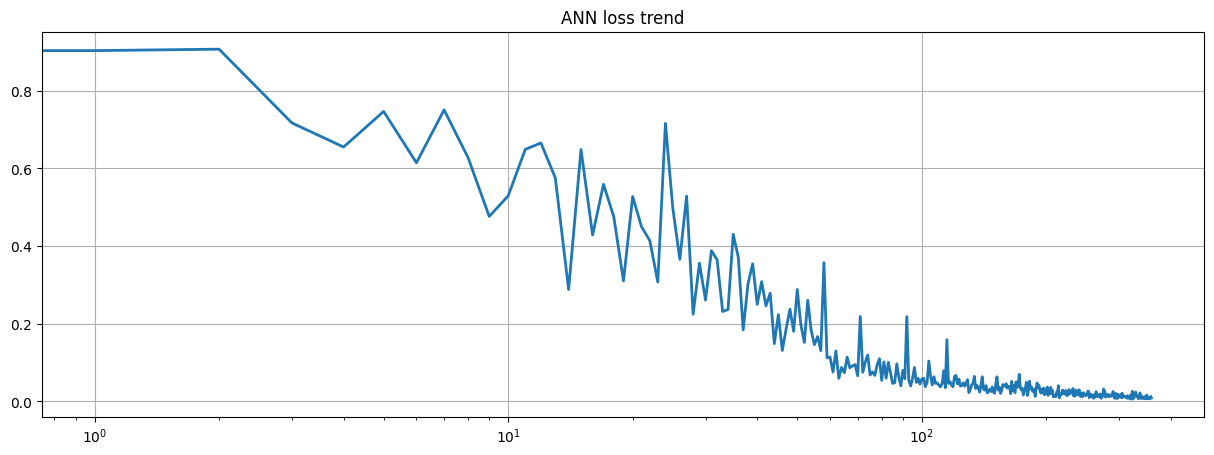

In [39]:
plt.figure(figsize=(15, 5))
plt.plot(ANN_losses, label = "loss")

plt.title("ANN loss trend")
plt.xscale("log")

plt.grid(True)

plt.show()

### **Testing**

In [40]:
def test_ANN(model, loss_function):
  dataset = MyANNDataset(X_test, y_test)
  loader_ANN = DataLoader(dataset, batch_size=32, shuffle=False)

  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader_ANN):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)

      outputs = model(x_batch)
      loss = loss_function(outputs, y_batch)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(outputs.cpu().numpy())

    actuals = y_test
    avg_loss = total_loss / len(loader_ANN.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [41]:
preds_ANN, actuals_ANN = test_ANN(model, loss_function)

Test Loss: 0.0347


### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **ANN** model compared to the actual data. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process.

In [166]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

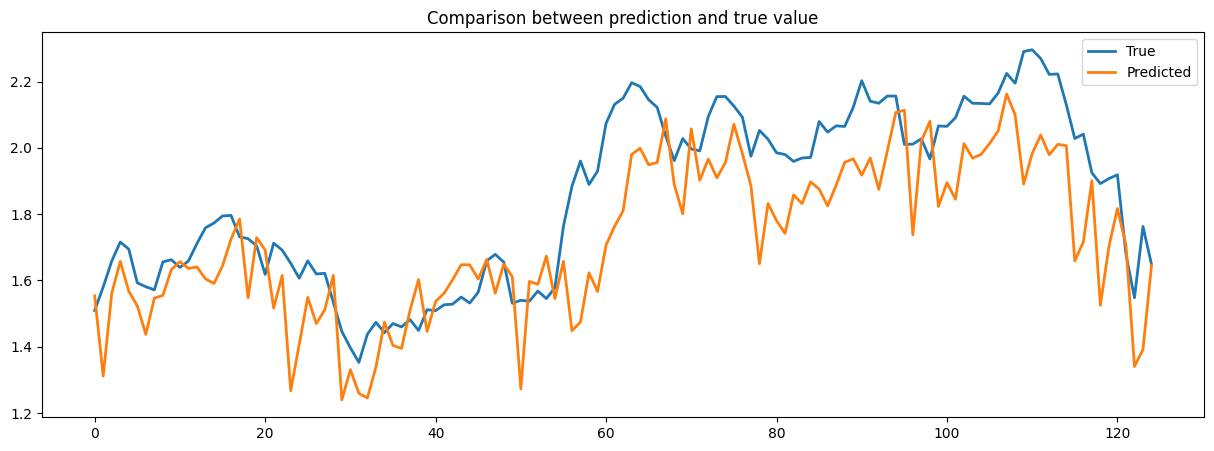

In [167]:
plot_predictions(preds_ANN, y_test)

##**SVR**

###**SVR implementation**

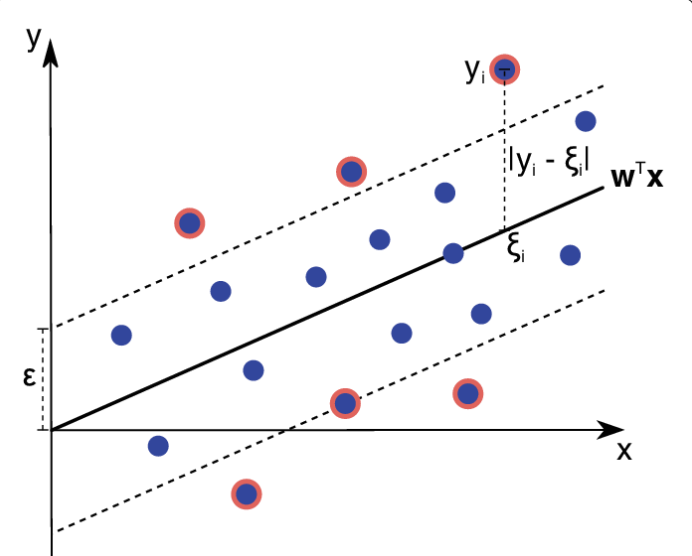

We implemented the SVR using sklearn.

In this example, a Support Vector Regression (SVR) model was trained to predict the closing values based on normalized features. The model uses a linear kernel with epsilon and C parameters chosen to control the tolerance margin and regularization. The predictions were returned to the original data scale, evaluated using Mean Squared Error (MSE) and plotted.

In [44]:
X = df_company.values
y = company_closings.values.flatten()

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()

# Split in train/test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.1, shuffle=False)
X_train, y_train = shuffle(X_train, y_train, random_state=42)

# SVR model with linear kernel
svr_model = SVR(epsilon=0.25, C=2, kernel='linear')
svr_model.fit(X_train, y_train)

y_pred_scaled = svr_model.predict(X_test)

y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
y_true = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()

#evaluation
mse = mean_squared_error(y_true, y_pred)
print("MSE:", mse)

preds_SVR = y_pred
actuals_SVR = y_true

MSE: 0.008316669239938705


###**Prediction results vs. true data**

The following graph illustrates the predictions made by our **SVR** model compared to the actual data. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process.

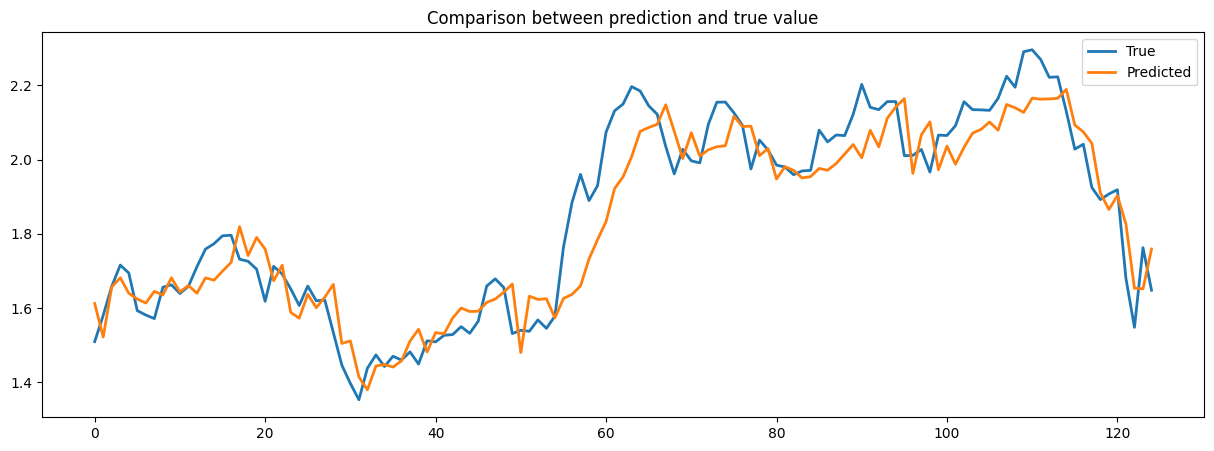

In [165]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

plot_predictions(y_pred, y_true)

## **LSTM (with Pytorch)**

Here we implement the **LSTM** using the **PyTorch** library, which provides **high-level modules** for defining the network and handling training efficiently.

### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [46]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

This class defines a custom PyTorch dataset for sequence data.
This class will be used to create a **data loader** that provides the inputs as **(batch_size, seq_len, input_size)** and the labels as **(batch_size, number of target features)**. This structure is necessary because, in this implementation, we use PyTorch libraries that require data to have these shapes.

In [47]:
class MyDataset(Dataset):
  def __init__(self, X_data, y_data, seq_len = 1):
    self.X_data = X_data
    self.y_data = y_data
    self.seq_len = seq_len

  def __len__(self):
    return len(self.y_data) - self.seq_len

  def __getitem__(self, idx):
    x = self.X_data[idx : idx + self.seq_len]
    y = self.y_data[idx + self.seq_len]
    return x, y

### **Pytorch LSTM implementation**

This is our PyTorch implementation of an LSTM model for time series prediction. The architecture consists of the following components:

 - **LSTM Layer**: Processes the input sequences and captures temporal dependencies
  - *input_size* specifies the number of features in each time step.
  - *hidden_size* is the number of features in the hidden state, controlling the model’s capacity to learn patterns.
  - *num_layers* allows stacking multiple LSTM layers to capture more complex sequential patterns.
  - *batch_first*=True ensures that the input tensor has shape (batch_size, seq_len, input_size), which aligns with our dataset loader.
  - *dropout*=0.3 applies dropout between LSTM layers (if stacked) to reduce overfitting.

 - **Fully Connected Layer**: Maps the hidden state of the last time step to the output prediction. Since we are predicting a single value (the **closing price**), the output dimension is 1.

In [48]:
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
      '''
        From pyorch documentation:
        * input_size – The number of expected features in the input x
        * hidden_size – The number of features in the hidden state h
        * num_layers – Number of recurrent layers.
          E.g., setting num_layers=2 would mean stacking two LSTMs together to form a stacked LSTM, with the second LSTM taking in outputs of the first LSTM and computing the final results. Default: 1

        * bias – If False, then the layer does not use bias weights b_ih and b_hh. Default: True
        * batch_first – If True, then the input and output tensors are provided as (batch, seq, feature) instead of (seq, batch, feature). Note that this does not apply to hidden or cell states. See the Inputs/Outputs sections below for details. Default: False
        * dropout – If non-zero, introduces a Dropout layer on the outputs of each LSTM layer except the last layer, with dropout probability equal to dropout. Default: 0
        * bidirectional – If True, becomes a bidirectional LSTM. Default: False
        * proj_size – If > 0, will use LSTM with projections of corresponding size. Default: 0
      '''
      super(LSTM, self).__init__()
      self.num_layers = num_layers
      self.hidden_size = hidden_size
      self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.3)
      self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
      # -> x needs to be: (batch_size, seq_len, input_size)
      # Set initial hidden states (and cell states for LSTM)
      h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size)
      c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size)

      # Forward propagate LSTM
      out, _ = self.lstm(x, (h0,c0))

      # out: tensor of shape (batch_size, seq_len, hidden_size)

      # Decode the hidden state of the last time step
      out = out[:, -1, :]
      out = self.fc(out)

      return out

### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found empirically to give the best results.

In [49]:
input_size = 5
hidden_size = 128
num_layers = 1
num_epochs = 500
lr = 0.00005
seq_len = 10

model = LSTM(input_size, hidden_size, num_layers)
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  warnings.warn(


### **Training**

At this stage, having chosen the **hyperparameters**, we perform the training of the network using PyTorch’s compact framework.

In [50]:
def train_LSTM(model, learning_rate, epochs, loss_function, optimizer, seq_len):
  # Train the model
  losses = []

  for epoch in range(epochs):

    dataset = MyDataset(X_train, y_train, seq_len = seq_len)
    loader = DataLoader(dataset, batch_size=32, shuffle=True)

    n_total_steps = len(loader)
    for i, (samples, labels) in enumerate(loader):
      # Forward pass
      outputs = model(samples)
      loss = loss_function(outputs, labels)

      losses.append(loss.item())
      # Backward and optimize
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

    if epoch % 50 == 0:
      print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

  print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

  return losses

In [51]:
losses = train_LSTM(model, lr, num_epochs, loss_function, optimizer, seq_len)

Epoch [1/500], Step [35/35], Loss: 0.4548
Epoch [51/500], Step [35/35], Loss: 0.0041
Epoch [101/500], Step [35/35], Loss: 0.0044
Epoch [151/500], Step [35/35], Loss: 0.0048
Epoch [201/500], Step [35/35], Loss: 0.0037
Epoch [251/500], Step [35/35], Loss: 0.0032
Epoch [301/500], Step [35/35], Loss: 0.0060
Epoch [351/500], Step [35/35], Loss: 0.0056
Epoch [401/500], Step [35/35], Loss: 0.0041
Epoch [451/500], Step [35/35], Loss: 0.0067
Epoch [500/500], Step [35/35], Loss: 0.0022


### **Learning of our LSTM**

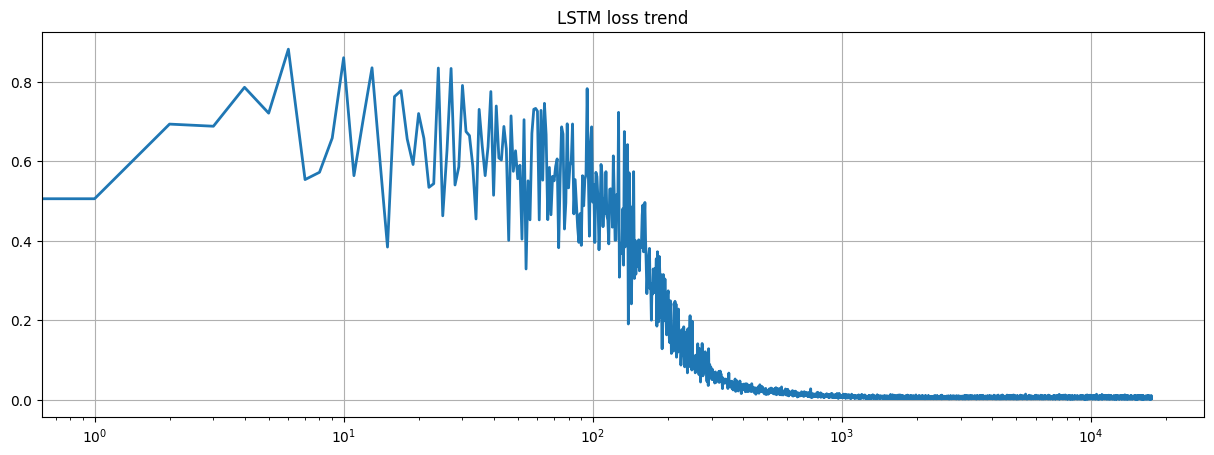

In [52]:
plt.figure(figsize=(15, 5))
plt.plot(losses, label = "loss")

plt.title("LSTM loss trend")
plt.xscale("log")

plt.grid(True)

plt.show()

### **Testing**

In [53]:
def test_LSTM(model, seq_len, loss_function):
  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):

      outputs = model(x_batch)
      loss = loss_function(outputs, y_batch)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(outputs.cpu().numpy())
      actuals.extend(y_batch.cpu().numpy())

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [54]:
preds_LSTM, actuals_LSTM = test_LSTM(model, seq_len, loss_function)

Test Loss: 0.0242


### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **LSTM** model compared to the actual data. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process.

In [55]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

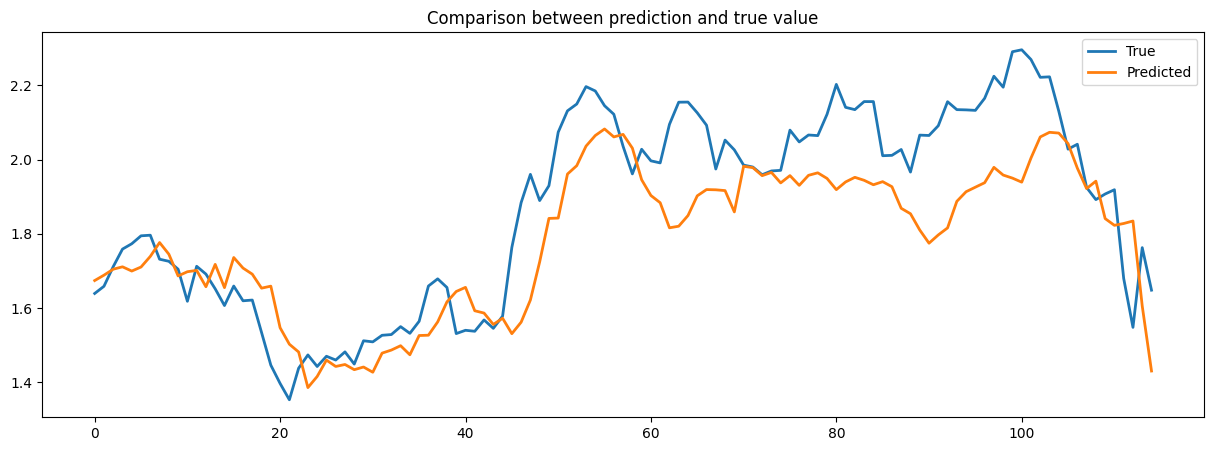

In [56]:
plot_predictions(preds_LSTM, actuals_LSTM)

## **GAN (with Pytorch)**

Generative Adversarial Networks (**GANs**) are a class of machine learning models, designed for generating new data that resembles a given dataset. The key idea behind GANs is the interaction between two neural networks: the **Generator** and the **Discriminator**.

The **Generator** aims to produce synthetic data that imitates the real data distribution.

The **Discriminator**, on the other hand, attempts to distinguish between real data (from the training set) and the fake data generated by the **Generator**.

This setup creates a **zero-sum game** (also called a minimax game), where the **Generator** continuously tries to fool the **Discriminator**, while the **Discriminator** improves its ability to detect fakes. Training proceeds until the **Generator** produces data so realistic that the **Discriminator** can no longer reliably tell the difference between real and generated samples.

The framework of GANs has had a major impact on artificial intelligence, enabling advances in image synthesis, data augmentation, and representation learning, among many other fields. In this chapter, we will explore how GANs work, their training dynamics, and their potential applications.

### **Procedure explanation**

The **generator** takes as input a sequence of daily stock data for $t$ days:

$$
X = \{x_1, x_2, \dots, x_t\}, \quad
x_k = [x_{k,High}, x_{k,Low}, x_{k,Open}, x_{k,Close}, x_{k,TurnoverRate}, x_{k,Volume}, x_{k,Ma5}]
$$

Each $x_k$ is a vector of 7 features representing one day of stock data.

The LSTM processes $X$ and produces a hidden state $h_t$:

$$
h_t = g(X)
$$

This hidden state is passed through a fully connected layer with weights $W_h$, bias $b_h$, and a Leaky ReLU activation $\delta(\cdot)$ to generate the next-day prediction:

$$
\hat{x}_{t+1} = \delta(W_h^T h_t + b_h)
$$

Here, $\hat{x}_{t+1,Close}$ is the predicted closing price.

To allow the **discriminator** to capture temporal correlations, the sequences are concatenated as follows:

**Fake sequence**:
$$
X_{fake} = \{x_1, \dots, x_t, \hat{x}_{t+1}\}
$$

**Real sequence:**
$$ X_{real} = \{x_1, \dots, x_t, x_{t+1}\} $$

The **discriminator** takes $X_{real}$ or $X_{fake}$ as input and outputs a probability:

$$
D(X_{fake}) = \sigma(d(X_{fake}))
$$
$$
D(X_{real}) = \sigma(d(X_{real}))
$$

where $d(\cdot)$ is the output of the MLP before the sigmoid function $\sigma(\cdot)$.

The **GAN** is trained using the standard minimax objective:

$$
\min_G \max_D V(G,D) = \mathbb{E}[\log D(X_{real})] + \mathbb{E}[\log (1 - D(X_{fake}))]
$$

The **discriminator loss** is calculated as:

$$
D_{loss} = -\frac{1}{m}\sum_{i=1}^m \Big( \log D(X_i^{real}) + \log (1 - D(X_i^{fake})) \Big)
$$

The **generator loss** combines the **adversarial loss** and a **Mean Squared Error (MSE)** term:

$$
g_{MSE} = \frac{1}{m} \sum_{i=1}^m (\hat{x}_{t+1}^i - x_{t+1}^i)^2
$$

$$
g_{loss} = \frac{1}{m}\sum_{i=1}^m \log (1 - D(X_i^{fake}))
$$

$$
G_{loss} = \lambda_1 g_{MSE} + \lambda_2 g_{loss}
$$

Here, $\lambda_1$ and $\lambda_2$ are hyperparameters controlling the balance between prediction accuracy and adversarial learning.

After training, the generator produces $\hat{x}_{t+1}$, particularly $\hat{x}_{t+1,Close}$, as the prediction of the next day’s closing price. The model can iteratively predict multiple days by concatenating each new prediction with the historical sequence to forecast further into the future.


### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [57]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [58]:
class MyGANDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx : idx + self.seq_len]

      return x, y

### **Discriminator and Generator**

In [59]:
class Discriminator(nn.Module):
  '''
    From paper:
      Here, we choose an MLP as our discriminator with three hidden layers h1,h2,h3 including 72, 100, 10 neurons, respectively.
      The Leaky ReLU is used as the activation function among the hidden layers and the sigmoid function is used in the output layer.
  '''
  def __init__(self, seq_len, n_features = 1):
    super().__init__()
    self.n_features = n_features
    self.seq_len = seq_len

    input_dim = self.seq_len * self.n_features
    self.model = nn.Sequential(

    # The input is two-dimensional, and the first hidden layer is composed of 256 neurons with ReLU activation.
    # The second and third hidden layers are composed of 128 and 64 neurons, respectively, with ReLU activation.
    # The output is composed of a single neuron with sigmoidal activation to represent a probability.
    # After the first, second, and third hidden layers, we use dropout to avoid overfitting.

      nn.Linear(input_dim, 72),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(72, 100),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(100, 10),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(10, 1),
      nn.Sigmoid(),
    )

  def forward(self, x):
    X_flat = x.view(x.size(0), -1)
    return self.model(X_flat)

In [60]:
class GeneratorLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, seq_len):
      '''
        * input_size – The number of expected features in the input x
        * hidden_size – The number of features in the hidden state h (dimensione hidden layer della lstm -> non dipende dai nostri dati, ma è un hyperparameter)
        * num_layers – Number of recurrent layers. (a quanto pare quanti strati di LSTM usiamo)
          E.g., setting num_layers=2 would mean stacking two LSTMs together to form a stacked LSTM, with the second LSTM taking in outputs of the first LSTM and computing the final results. Default: 1

        * bias – If False, then the layer does not use bias weights b_ih and b_hh. Default: True
        * batch_first – If True, then the input and output tensors are provided as (batch, seq, feature) instead of (seq, batch, feature). Note that this does not apply to hidden or cell states. See the Inputs/Outputs sections below for details. Default: False
        * dropout – If non-zero, introduces a Dropout layer on the outputs of each LSTM layer except the last layer, with dropout probability equal to dropout. Default: 0
        * bidirectional – If True, becomes a bidirectional LSTM. Default: False
        * proj_size – If > 0, will use LSTM with projections of corresponding size. Default: 0
      '''
      super(GeneratorLSTM, self).__init__()
      self.num_layers = num_layers
      self.hidden_size = hidden_size
      self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.3)
      self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
      # Set initial hidden states (and cell states for LSTM)
      h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
      c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)

      # Forward propagate LSTM
      out, _ = self.lstm(x, (h0,c0))

      # out shape (batch_size, seq_len, hidden_size)
      out = out[:, :, :]
      out = self.fc(out)

      return out

### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found empirically to give the best results.

In [61]:
input_size = 5
hidden_size = 128
num_layers = 1
num_epochs = 500
lr = 0.00005
seq_len = 10

generator = GeneratorLSTM(input_size, hidden_size, num_layers, seq_len)
discriminator = Discriminator(seq_len)
generator_optimizer = torch.optim.Adam(generator.parameters(), lr=lr)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=lr)

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  warnings.warn(


### **Training**

The **GAN** is trained using the minimax optimization:

$$
\min_G \max_D V(G,D) = \mathbb{E}[\log D(X_{real})] + \mathbb{E}[\log (1 - D(X_{fake}))]
$$

The **discriminator loss** is:
$$
D_{loss} = -\frac{1}{m}\sum_{i=1}^m \Big( \log D(X_i^{real}) + \log (1 - D(X_i^{fake})) \Big)
$$

The **generator loss** is a combination of the classical GAN loss and the **Mean Squared Error** (**MSE**):
$$
g_{MSE} = \frac{1}{m} \sum_{i=1}^m (\hat{x}_{t+1}^i - x_{t+1}^i)^2
$$

$$
g_{loss} = \frac{1}{m}\sum_{i=1}^m \log (1 - D(X_i^{fake}))
$$

$$
G_{loss} = \lambda_1 g_{MSE} + \lambda_2 g_{loss}
$$

where $\lambda_1$ and $\lambda_2$ are hyperparameters controlling the trade-off between **prediction accuracy** and **adversarial learning**.

In [62]:
def get_fake_labels(real_labels, output_LSTM):
  # real_labels (batch_size, seq_len, 1)
  # output_LSTM (batch_size, seq_len, 1)

  last_step_output = output_LSTM[:, -1, :]

  y_fake = real_labels.clone()
  y_fake[:, -1, :] = last_step_output

  return y_fake

In [63]:
def discriminator_loss(D_real, D_fake):
    loss = -torch.mean(torch.log(D_real) + torch.log(1 - D_fake))
    return loss

def generator_loss(D_fake, output_LSTM, y_real, lambda1=0.7, lambda2=0.3):
    # MSE component
    mse_loss = F.mse_loss(output_LSTM, y_real)

    # Adversarial gloss component
    adv_loss = torch.mean(torch.log(1 - D_fake))

    # Total generator loss
    return lambda1 * mse_loss + lambda2 * adv_loss

In [64]:
def train_GAN(
    generator,
    discriminator,
    learning_rate_discriminator,
    learning_rate_generator,
    epochs,
    generator_loss,
    discriminator_loss,
    generator_optimizer,
    discriminator_optimizer,
    seq_len,
    batch_size = 32):

  dataset_real = MyGANDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset_real, batch_size=batch_size, shuffle=True)
  n_total_steps = len(loader)
  D_losses = []
  G_losses = []

  generator.to(device)
  discriminator.to(device)

  for epoch in range(epochs):
    for i, (samples, labels) in enumerate(loader):
      X_real = samples.to(device)
      y_real = labels.to(device)

      output_LSTM = generator(X_real)
      y_fake = get_fake_labels(y_real, output_LSTM)

      # Training the discriminator
      discriminator.zero_grad()
      output_discriminator_real = discriminator(y_real)
      output_discriminator_fake = discriminator(y_fake)

      loss_discriminator = discriminator_loss(
        output_discriminator_real, output_discriminator_fake)

      D_losses.append(loss_discriminator.item())

      # We calculate the gradients to update the weights with loss_discriminator.backward()
      loss_discriminator.backward()
      # We update the discriminator weights by calling optimizer_discriminator.step()
      discriminator_optimizer.step()

      # Training the generator
      generator.zero_grad()

      output_LSTM = generator(X_real)
      y_fake = get_fake_labels(y_real, output_LSTM)

      output_discriminator_generated = discriminator(y_fake)

      # we calculate the loss function using the output of the classification system stored in output_discriminator_generated
      # and the labels in real_samples_labels, which are all equal to 1.
      loss_generator = generator_loss(
        output_discriminator_generated, output_LSTM, y_real
      )

      G_losses.append(loss_generator.item())

      loss_generator.backward()
      generator_optimizer.step()

    # Show loss
    if epoch % 50 == 0:
      print(f"Epoch: {epoch} Loss D.: {loss_discriminator}")
      print(f"Epoch: {epoch} Loss G.: {loss_generator}")

  return D_losses, G_losses

In [65]:
discriminator_losses, generator_losses = train_GAN(
    generator,
    discriminator,
    lr,
    lr,
    num_epochs,
    generator_loss,
    discriminator_loss,
    generator_optimizer,
    discriminator_optimizer,
    seq_len)

Epoch: 0 Loss D.: 1.4073615074157715
Epoch: 0 Loss G.: 0.22788265347480774
Epoch: 50 Loss D.: 1.3779497146606445
Epoch: 50 Loss G.: -0.17538224160671234
Epoch: 100 Loss D.: 1.3889844417572021
Epoch: 100 Loss G.: -0.19086578488349915
Epoch: 150 Loss D.: 1.392952561378479
Epoch: 150 Loss G.: -0.2034951001405716
Epoch: 200 Loss D.: 1.3754700422286987
Epoch: 200 Loss G.: -0.20527292788028717
Epoch: 250 Loss D.: 1.3876947164535522
Epoch: 250 Loss G.: -0.20597383379936218
Epoch: 300 Loss D.: 1.3848942518234253
Epoch: 300 Loss G.: -0.2058311104774475
Epoch: 350 Loss D.: 1.384765863418579
Epoch: 350 Loss G.: -0.20646214485168457
Epoch: 400 Loss D.: 1.3843713998794556
Epoch: 400 Loss G.: -0.20590169727802277
Epoch: 450 Loss D.: 1.3851383924484253
Epoch: 450 Loss G.: -0.2076742798089981


### **Testing**

In [66]:
def test_GAN(model, seq_len, loss_function):
  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyGANDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)
      outputs = model(x_batch)
      last_step_output = outputs[:, -1, :]

      last_step_label = y_batch[:, -1, :]

      loss = loss_function(last_step_output, last_step_label)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(last_step_output.cpu().numpy())
      actuals.extend(last_step_label.cpu().numpy())

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [67]:
preds_GAN, actuals_GAN = test_GAN(generator, seq_len, nn.MSELoss())

Test Loss: 0.0135


### **Learning of our GAN**

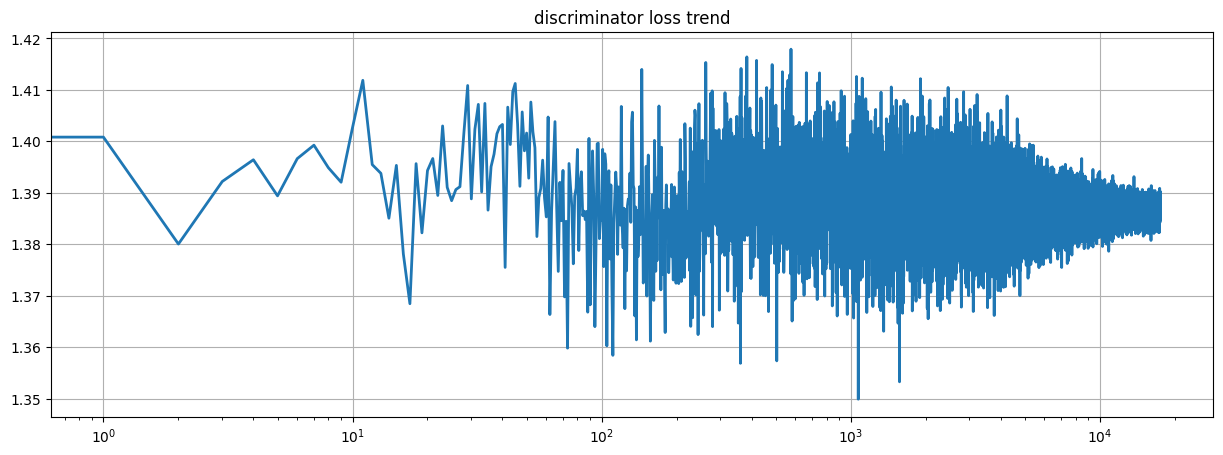

In [68]:
plt.figure(figsize=(15, 5))
plt.plot(discriminator_losses, label = "D_loss")

plt.title("discriminator loss trend")
plt.xscale('log')

plt.grid(True)

plt.show()

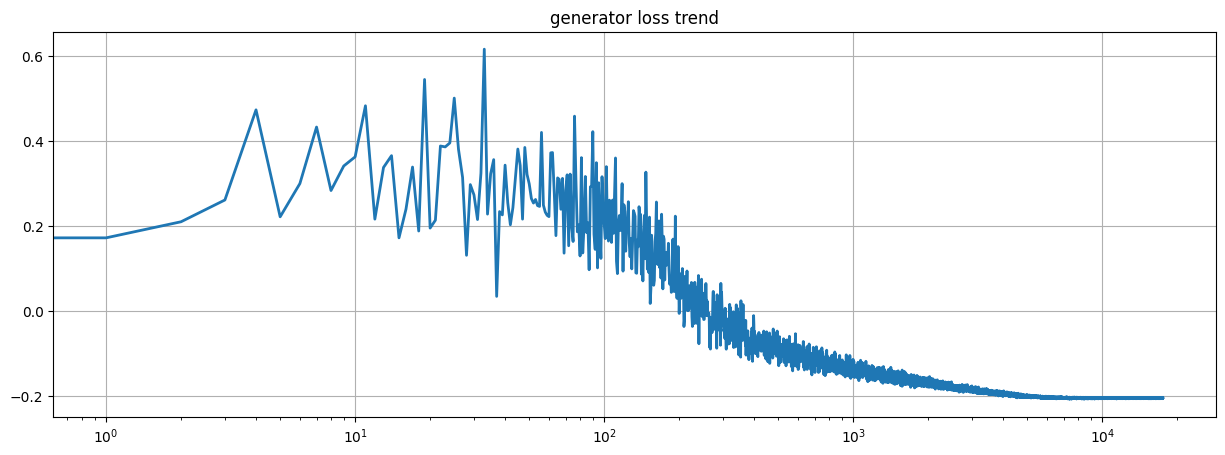

In [69]:
plt.figure(figsize=(15, 5))
plt.plot(generator_losses, label = "G_loss")

plt.title("generator loss trend")
plt.xscale('log')

plt.grid(True)

plt.show()

### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **GAN** model compared to the **actual data**. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process.

In [70]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

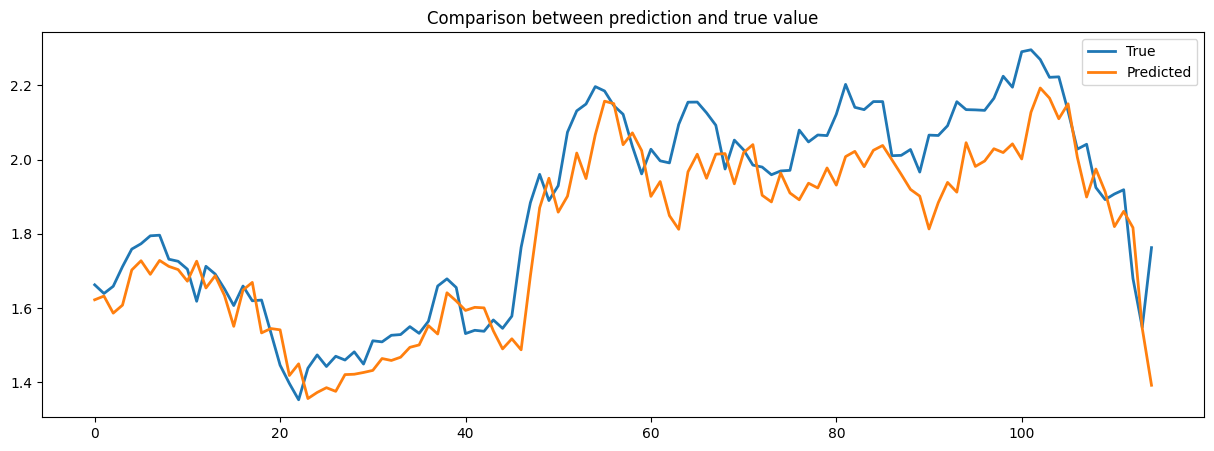

In [71]:
plot_predictions(preds_GAN, actuals_GAN)

##**LSTM (from scratch)**

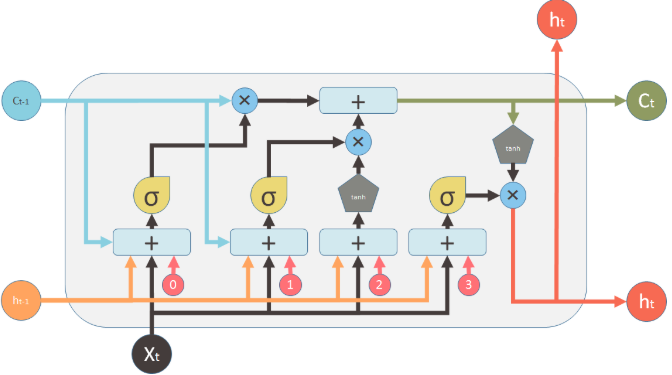

In the following section, we will implement an **LSTM** using standard **JAX** libraries together with **JIT** compilation. JAX allows us to define the model and training loop in a NumPy-like syntax, while jit compiles these operations into highly **optimized code**. This compilation enables efficient parallel execution and full utilization of GPU acceleration.

During training, the forward and backward passes are transformed into **optimized computational graphs**, allowing gradient computations and parameter updates to be executed much faster than with a purely Python implementation. Thanks to these optimizations, the training process becomes feasible in terms of execution time, even for models working on large sequential datasets.

In [72]:
print(jax.devices())

[CpuDevice(id=0)]


### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [73]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

This class defines a custom PyTorch dataset for sequence data.
In this case, the dataset will be used to train an LSTM implemented from scratch. We still rely on the dataset and data loader to keep **consistency** between the two implementations, providing the inputs as **(batch_size, seq_len, input_size)** and the labels as **(batch_size, number of target features)**.

In [74]:
class MyDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx + self.seq_len]

      return x, y

In [75]:
def mse_loss(y_pred, y_true):
    return jnp.mean((y_pred - y_true) ** 2)

In [76]:
def sigmoid(x):
    return 1.0 / (1.0 + jnp.exp(-x))

def dsigmoid_from_output(s):
    # s = sigmoid(x)
    return s * (1 - s)

def dtanh_from_output(t):
    # t = tanh(x)
    return 1 - t ** 2

In [77]:
chosen_loss = mse_loss

### **Implementation**

In [78]:
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    return h_t, s_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), h_t

    (h_final, s_final), H_seq = lax.scan(step_scan, (h0, s0), X)
    h_last = H_seq[-1]

    y = params['V'] @ h_last + params['b_out']
    return y  # (output_size,)

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])

class LSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Weight initialization
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)


### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found **empirically** to give the best results.

In [79]:
input_size = 5
hidden_size = 48
num_epochs = 500
lr = 0.055
seq_len = 5
output_size = 1

key = random.PRNGKey(0)
model = LSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)

### **Training**

At this stage, having chosen the **hyperparameters**, we perform the training of the network using our LSTM implementation from scratch, relying on **JAX** and **JIT** to efficiently handle **gradient computations** and **parameter updates**.

In [80]:
def train_step(params, X_batch, Y_batch, lr, model, loss_function):
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        return loss_function(Y_pred, Y_batch)

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_jit = jax.jit(train_step, static_argnames=['model', 'loss_function'])

def train_LSTM_scratch(model, X_train, y_train, seq_len, loss_function, batch_size=32, learning_rate=0.001, epochs=500):
    """
    Training loop
    X_train: array (num_samples, seq_len, input_size)
    y_train: array (num_samples, output_size)
    """

    dataset = MyDataset(X_train, y_train, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    losses = []

    for epoch in range(epochs):
        epoch_loss = 0.0

        for samples, labels in loader:
            # Conversion in jax arrays
            X_batch = jnp.array(samples, dtype=jnp.float32)
            Y_batch = jnp.array(labels, dtype=jnp.float32)

            # Update of the model parameters
            model.params = train_step_jit(model.params, X_batch, Y_batch, learning_rate, model, loss_function)

            # Batch loss
            Y_pred = model.forward_batch(model.params, X_batch)
            batch_loss = loss_function(Y_pred, Y_batch)
            losses.append(batch_loss)
            epoch_loss += batch_loss

        avg_loss = epoch_loss / len(loader)


        if (epoch+1) % 50 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.6f} [{datetime.now()}]')

    return losses


In [81]:
losses = train_LSTM_scratch(model, X_train, y_train, loss_function=chosen_loss, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)

/tmp/ipython-input-1174771072.py:7: DeprecationWarning: jax.tree_map is deprecated: use jax.tree.map (jax v0.4.25 or newer) or jax.tree_util.tree_map (any JAX version).
  new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)


Epoch [50/500], Loss: 0.005524 [2025-09-06 08:05:52.697605]
Epoch [100/500], Loss: 0.005206 [2025-09-06 08:05:57.579403]
Epoch [150/500], Loss: 0.005070 [2025-09-06 08:06:04.629021]
Epoch [200/500], Loss: 0.004900 [2025-09-06 08:06:09.757993]
Epoch [250/500], Loss: 0.004871 [2025-09-06 08:06:16.849846]
Epoch [300/500], Loss: 0.004797 [2025-09-06 08:06:21.764953]
Epoch [350/500], Loss: 0.004726 [2025-09-06 08:06:26.645655]
Epoch [400/500], Loss: 0.004679 [2025-09-06 08:06:33.805326]
Epoch [450/500], Loss: 0.004674 [2025-09-06 08:06:38.696314]
Epoch [500/500], Loss: 0.004596 [2025-09-06 08:06:45.657967]


### **Learning of our LSTM**

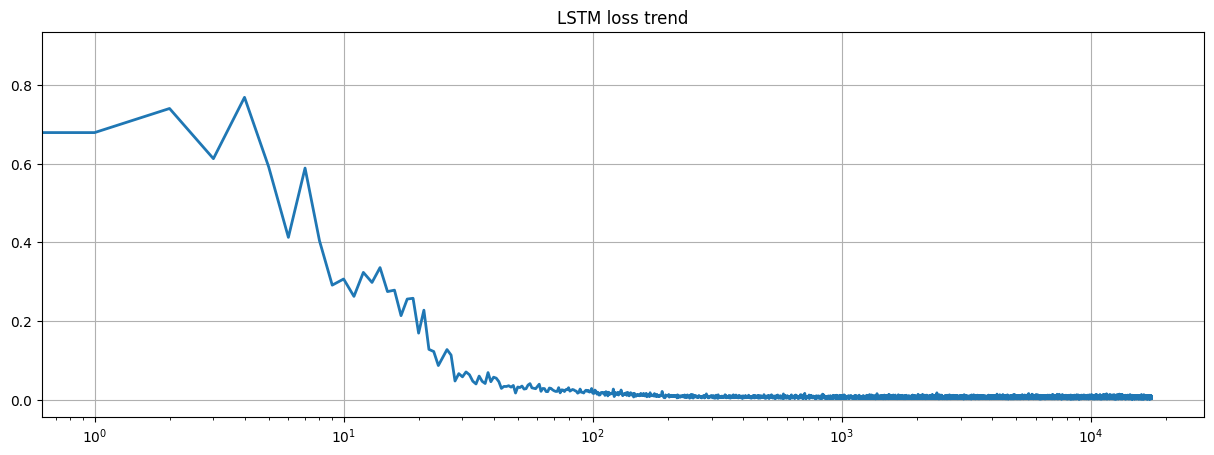

In [82]:
plt.figure(figsize=(15, 5))
plt.plot(losses, label = "loss")

plt.title("LSTM loss trend")
plt.xscale('log')

plt.grid(True)

plt.show()

### **Testing**

In [83]:
def test_LSTM_scratch(model, X_test, y_test, seq_len, loss_function, batch_size=32):
    total_loss = 0
    preds = []
    actuals = []

    dataset = MyDataset(X_test, y_test, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for x_batch, y_batch in loader:
        X_batch = jnp.array(x_batch, dtype=jnp.float32)
        Y_batch = jnp.array(y_batch, dtype=jnp.float32)

        Y_pred = model.forward_batch(model.params, X_batch)

        loss = loss_function(Y_pred, Y_batch)
        total_loss += loss * X_batch.shape[0]

        preds.extend(np.array(Y_pred))
        actuals.extend(np.array(Y_batch))

    avg_loss = total_loss / len(loader.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

    return preds, actuals

In [84]:
preds_LSTM_scratch, actuals_LSTM_scratch = test_LSTM_scratch(model, X_test, y_test, seq_len=seq_len, loss_function=chosen_loss)

Test Loss: 0.0165


### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **LSTM** model compared to the **actual data**. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process. Moreover, the results are **comparable to those obtained with the PyTorch implementation**, which suggests that we have achieved a solid level of precision.

In [85]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

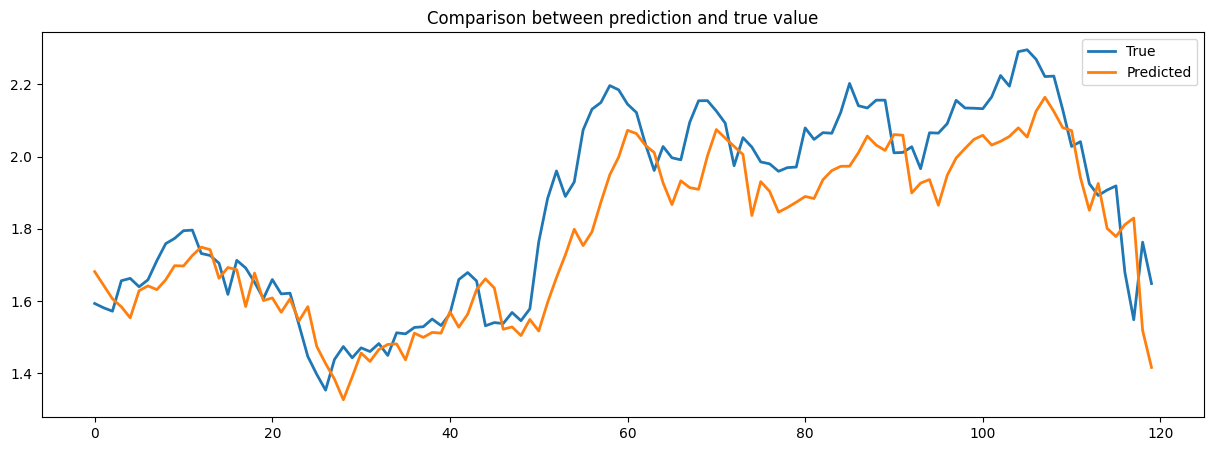

In [86]:
plot_predictions(preds_LSTM_scratch, actuals_LSTM_scratch)

##**GAN (with LSTM from scratch)**

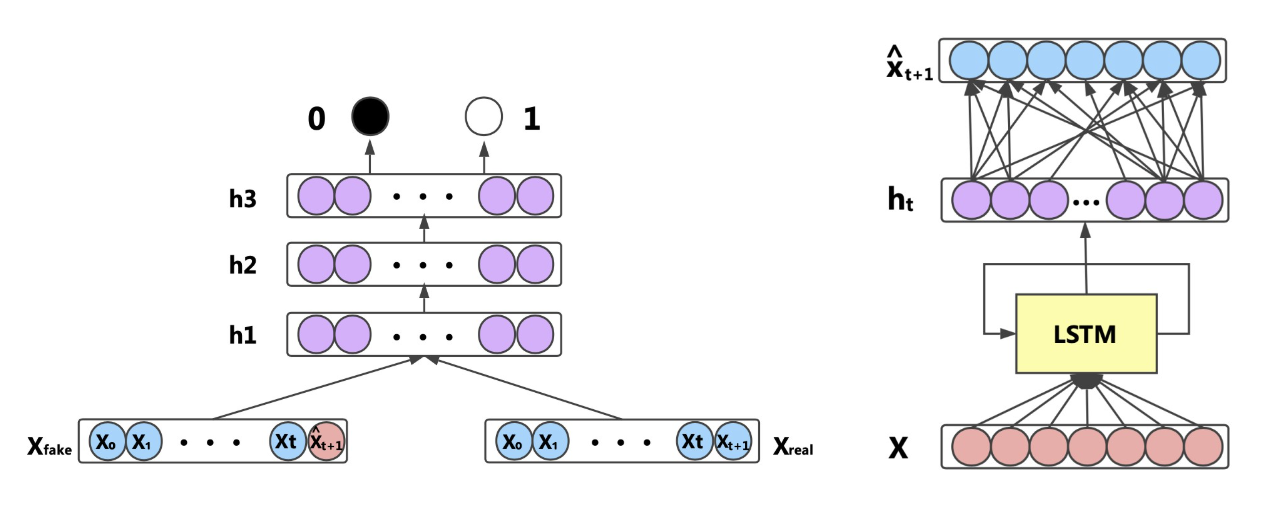

Generative Adversarial Networks (**GANs**) are a class of machine learning models, designed for generating new data that resembles a given dataset. The key idea behind GANs is the interaction between two neural networks: the **Generator** and the **Discriminator**.

The **Generator** aims to produce synthetic data that imitates the real data distribution.

The **Discriminator**, on the other hand, attempts to distinguish between real data (from the training set) and the fake data generated by the **Generator**.

This setup creates a **zero-sum game** (also called a minimax game), where the **Generator** continuously tries to fool the **Discriminator**, while the **Discriminator** improves its ability to detect fakes. Training proceeds until the **Generator** produces data so realistic that the **Discriminator** can no longer reliably tell the difference between real and generated samples.

The framework of GANs has had a major impact on artificial intelligence, enabling advances in image synthesis, data augmentation, and representation learning, among many other fields. In this chapter, we will explore how GANs work, their training dynamics, and their potential applications.

### **Procedure explanation**

The **generator** takes as input a sequence of daily stock data for $t$ days:

$$
X = \{x_1, x_2, \dots, x_t\}, \quad
x_k = [x_{k,High}, x_{k,Low}, x_{k,Open}, x_{k,Close}, x_{k,TurnoverRate}, x_{k,Volume}, x_{k,Ma5}]
$$

Each $x_k$ is a vector of 7 features representing one day of stock data.

The LSTM processes $X$ and produces a hidden state $h_t$:

$$
h_t = g(X)
$$

This hidden state is passed through a fully connected layer with weights $W_h$, bias $b_h$, and a Leaky ReLU activation $\delta(\cdot)$ to generate the next-day prediction:

$$
\hat{x}_{t+1} = \delta(W_h^T h_t + b_h)
$$

Here, $\hat{x}_{t+1,Close}$ is the predicted closing price.

To allow the **discriminator** to capture temporal correlations, the sequences are concatenated as follows:

**Fake sequence**:
$$
X_{fake} = \{x_1, \dots, x_t, \hat{x}_{t+1}\}
$$

**Real sequence:**
$$ X_{real} = \{x_1, \dots, x_t, x_{t+1}\} $$

The **discriminator** takes $X_{real}$ or $X_{fake}$ as input and outputs a probability:

$$
D(X_{fake}) = \sigma(d(X_{fake}))
$$
$$
D(X_{real}) = \sigma(d(X_{real}))
$$

where $d(\cdot)$ is the output of the MLP before the sigmoid function $\sigma(\cdot)$.

The **GAN** is trained using the standard minimax objective:

$$
\min_G \max_D V(G,D) = \mathbb{E}[\log D(X_{real})] + \mathbb{E}[\log (1 - D(X_{fake}))]
$$

The **discriminator loss** is calculated as:

$$
D_{loss} = -\frac{1}{m}\sum_{i=1}^m \Big( \log D(X_i^{real}) + \log (1 - D(X_i^{fake})) \Big)
$$

The **generator loss** combines the **adversarial loss** and a **Mean Squared Error (MSE)** term:

$$
g_{MSE} = \frac{1}{m} \sum_{i=1}^m (\hat{x}_{t+1}^i - x_{t+1}^i)^2
$$

$$
g_{loss} = \frac{1}{m}\sum_{i=1}^m \log (1 - D(X_i^{fake}))
$$

$$
G_{loss} = \lambda_1 g_{MSE} + \lambda_2 g_{loss}
$$

Here, $\lambda_1$ and $\lambda_2$ are hyperparameters controlling the balance between prediction accuracy and adversarial learning.

After training, the generator produces $\hat{x}_{t+1}$, particularly $\hat{x}_{t+1,Close}$, as the prediction of the next day’s closing price. The model can iteratively predict multiple days by concatenating each new prediction with the historical sequence to forecast further into the future.


### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [118]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [119]:
class MyGANDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx : idx + self.seq_len]

      return x, y

### **Discriminator and Generator**

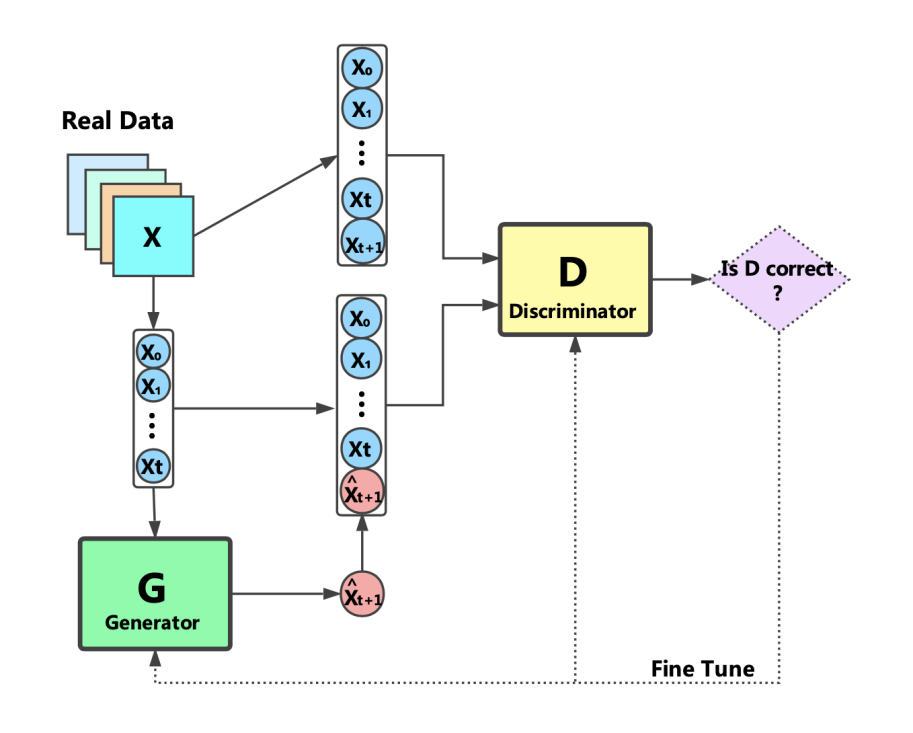

In [120]:
class Discriminator(nn.Module):
  '''
    From paper:
      Here, we choose an MLP as our discriminator with three hidden layers h1,h2,h3 including 72, 100, 10 neurons, respectively.
      The Leaky ReLU is used as the activation function among the hidden layers and the sigmoid function is used in the output layer.
  '''
  def __init__(self, seq_len, n_features = 1):
    super().__init__()
    self.n_features = n_features
    self.seq_len = seq_len

    input_dim = self.seq_len * self.n_features
    self.model = nn.Sequential(

    # The input is two-dimensional (perchè ho un MLP), and the first hidden layer is composed of 256 neurons with ReLU activation.
    # The second and third hidden layers are composed of 128 and 64 neurons, respectively, with ReLU activation.
    # The output is composed of a single neuron with sigmoidal activation to represent a probability.
    # After the first, second, and third hidden layers, we use dropout to avoid overfitting.
      nn.Linear(input_dim, 72),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(72, 100),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(100, 10),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(10, 1),
      nn.Sigmoid(),
    )

  # We use .forward() to describe how the output of the model is calculated.
  # Here, x represents the input of the model, which is a two-dimensional tensor.
  # In this implementation, the output is obtained by feeding the input x to the model we’ve defined without any other processing.

  def forward(self, x):
    X_flat = x.view(x.size(0), -1)
    return self.model(X_flat)

In [121]:
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    return h_t, s_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), h_t

    (h_final, s_final), H_seq = lax.scan(step_scan, (h0, s0), X)

    Y_seq = H_seq @ params['V'].T + params['b_out']

    return Y_seq

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])



In [122]:
class GeneratorLSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Weight initialization
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)

### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found empirically to give the best results.

In [123]:
input_size = 5
hidden_size = 48
num_layers = 1
num_epochs = 500
lr_D = 0.005
lr_G =0.075
seq_len = 5

generator = GeneratorLSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)
discriminator = Discriminator(seq_len)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=lr_D)

### **Training**

In [124]:
def get_fake_labels(real_labels, output_LSTM):
    # real_labels (batch_size, seq_len, 1)
    # output_LSTM (batch_size, seq_len, 1)

    last_step_output = output_LSTM[:, -1, :]

    y_fake = jnp.array(real_labels, dtype=jnp.float32)
    y_fake = y_fake.at[:, -1, :].set(last_step_output)
    return torch.tensor(np.array(y_fake), dtype=torch.float32)

In [125]:
def discriminator_loss(D_real, D_fake):
    loss = -torch.mean(torch.log(D_real) + torch.log(1 - D_fake))
    return loss

def generator_loss(D_fake, output_LSTM, y_real, lambda1=0.7, lambda2=0.3):
    # MSE component
    mse_loss_val = mse_loss(output_LSTM, y_real)

    # Adversarial gloss component
    adv_loss = jnp.mean(jnp.log(1 - D_fake))

    # Total generator loss
    return lambda1 * mse_loss_val + lambda2 * adv_loss

In [126]:
def train_step_generator(params, X_batch, Y_batch, lr, model, generator_loss, D_out):
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        return generator_loss(D_out, Y_pred, Y_batch)

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_generator_jit = jax.jit(train_step_generator, static_argnames=['model', 'generator_loss'])



def train_GAN_scratch(
    generator,
    discriminator,
    learning_rate_discriminator,
    learning_rate_generator,
    epochs,
    generator_loss,
    discriminator_loss,
    discriminator_optimizer,
    seq_len,
    batch_size = 32):

  dataset_real = MyGANDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset_real, batch_size=batch_size, shuffle=True)
  n_total_steps = len(loader)
  D_losses = []
  G_losses = []

  for epoch in range(epochs):
    for i, (x_real, y_real) in enumerate(loader):

      X_batch = jnp.array(x_real, dtype=jnp.float32)
      Y_batch = jnp.array(y_real, dtype=jnp.float32)
      output_LSTM = generator.forward_batch(generator.params, X_batch)
      y_fake = get_fake_labels(y_real, output_LSTM)

      # Training the discriminator

      discriminator.zero_grad()
      output_discriminator_real = discriminator(y_real)
      output_discriminator_fake = discriminator(y_fake)

      loss_discriminator = discriminator_loss(
        output_discriminator_real, output_discriminator_fake)

      D_losses.append(loss_discriminator.item())

      loss_discriminator.backward()
      discriminator_optimizer.step()

      # Training the generator

      # Batch loss
      output_LSTM = generator.forward_batch(generator.params, X_batch)

      Y_fake = get_fake_labels(Y_batch, output_LSTM)

      output_discriminator_generated = discriminator(Y_fake)

      D_output_array = jnp.array(output_discriminator_generated.detach().cpu().numpy(), dtype=jnp.float32)
      loss_generator = generator_loss(
        D_output_array, output_LSTM, Y_batch
      )

      G_losses.append(loss_generator.item())

      generator.params = train_step_generator_jit(generator.params, X_batch, Y_batch, learning_rate_generator, generator, generator_loss, D_output_array)

    if epoch % 50 == 0:
      print(f"Epoch: {epoch} Loss D.: {loss_discriminator}")
      print(f"Epoch: {epoch} Loss G.: {loss_generator}")

  return D_losses, G_losses

In [127]:
discriminator_losses, generator_losses = train_GAN_scratch(
    generator,
    discriminator,
    lr_D,
    lr_G,
    num_epochs,
    generator_loss,
    discriminator_loss,
    discriminator_optimizer,
    seq_len)

Epoch: 0 Loss D.: 1.169945240020752
Epoch: 0 Loss G.: -0.020471885800361633
Epoch: 50 Loss D.: 1.3298674821853638
Epoch: 50 Loss G.: -0.19972604513168335
Epoch: 100 Loss D.: 1.2485641241073608
Epoch: 100 Loss G.: -0.19017551839351654
Epoch: 150 Loss D.: 1.1957359313964844
Epoch: 150 Loss G.: -0.11876802891492844
Epoch: 200 Loss D.: 1.2001793384552002
Epoch: 200 Loss G.: -0.16585497558116913
Epoch: 250 Loss D.: 1.081092357635498
Epoch: 250 Loss G.: -0.20135720074176788
Epoch: 300 Loss D.: 1.1825993061065674
Epoch: 300 Loss G.: -0.16516055166721344
Epoch: 350 Loss D.: 1.0180929899215698
Epoch: 350 Loss G.: -0.15692681074142456
Epoch: 400 Loss D.: 1.0678349733352661
Epoch: 400 Loss G.: -0.16694913804531097
Epoch: 450 Loss D.: 1.2471611499786377
Epoch: 450 Loss G.: -0.14292922616004944


### **Learning of our GAN**

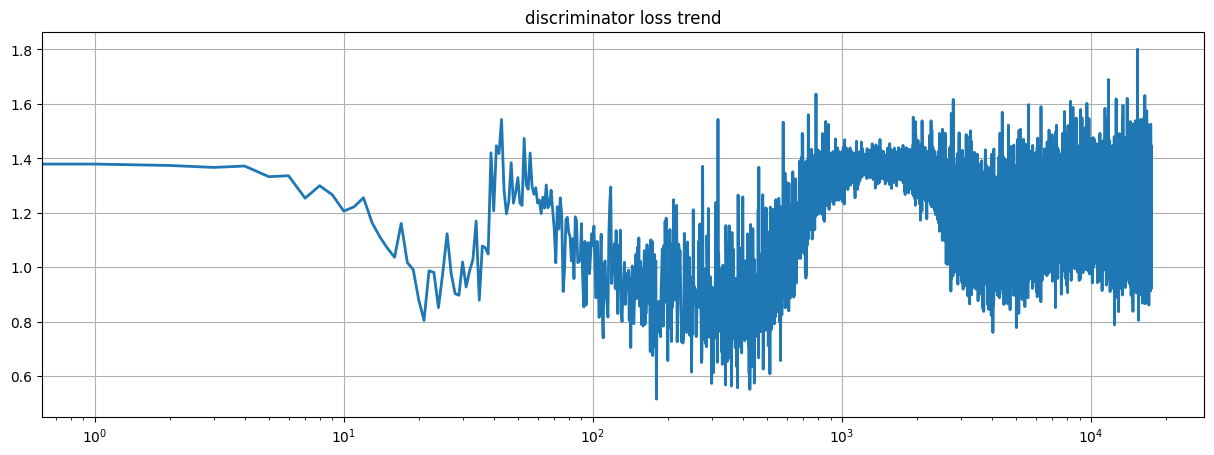

In [128]:
plt.figure(figsize=(15, 5))
plt.plot(discriminator_losses, label = "D_loss")

plt.title("discriminator loss trend")
plt.xscale('log')

plt.grid(True)


plt.show()

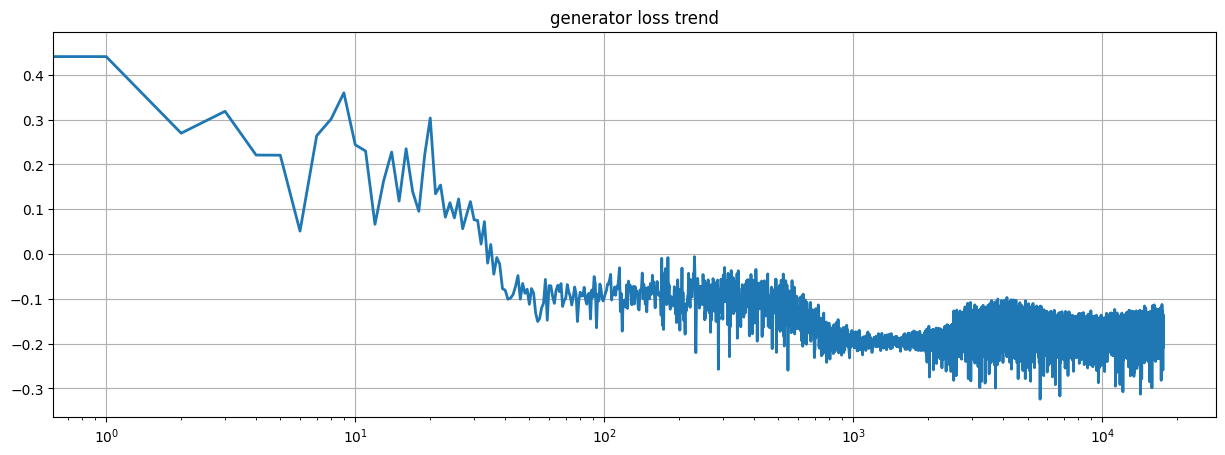

In [129]:
plt.figure(figsize=(15, 5))
plt.plot(generator_losses, label = "G_loss")

plt.title("generator loss trend")
plt.xscale('log')

plt.grid(True)

plt.show()

### **Testing**

In [130]:
def test_GAN_scratch(model, seq_len, loss_function):
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyGANDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      X_batch = jnp.array(x_batch, dtype=jnp.float32)
      Y_batch = jnp.array(y_batch, dtype=jnp.float32)
      outputs = model.forward_batch(model.params, X_batch)

      last_step_output = outputs[:, -1, :]

      last_step_label = Y_batch[:, -1, :]

      loss = loss_function(last_step_output, last_step_label)

      total_loss += loss * X_batch.shape[0]

      preds.extend(last_step_output)
      actuals.extend(last_step_label)

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [131]:
preds_GAN_scratch, actuals_GAN_scratch = test_GAN_scratch(generator, seq_len, chosen_loss)

Test Loss: 0.0054


### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **GAN** model compared to the **actual data**. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process. Moreover, the results are **comparable to those obtained with the PyTorch implementation**, which suggests that we have achieved a solid level of precision.

In [132]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

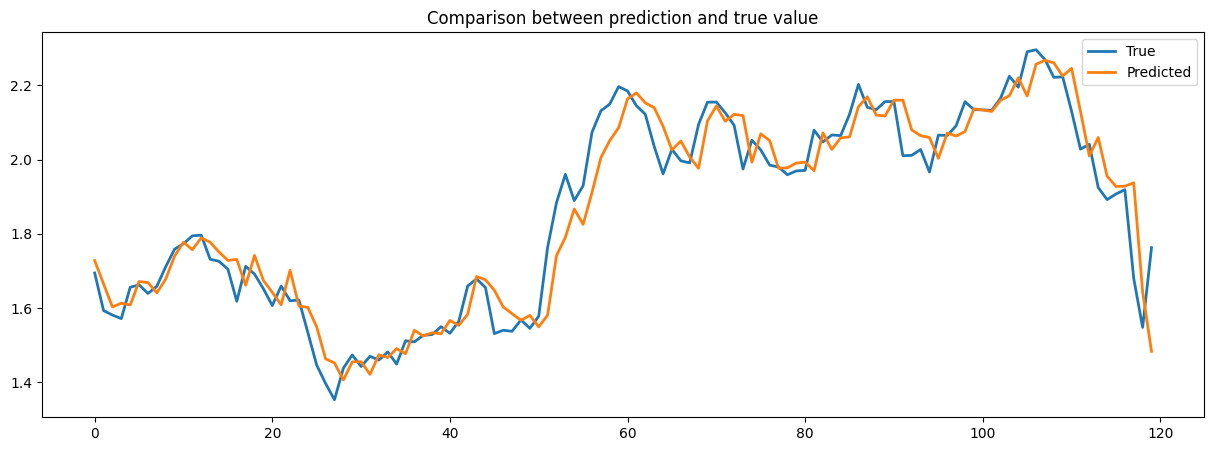

In [133]:
plot_predictions(preds_GAN_scratch, actuals_GAN_scratch)

## **Comparison**

### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [134]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [135]:
class MyGANDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx : idx + self.seq_len]

      return x, y

###**Best Learning rate for GAN**

In [136]:
input_size = 5
hidden_size = 48
num_layers = 1
num_epochs = 500
lr_D = 0.005
lrs = [0.025, 0.05, 0.075, 0.1]
seq_len = 5

In [137]:
preds_GAN_arr = []
actuals_GAN_arr = []

for lr in lrs:
  generator = GeneratorLSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)
  discriminator = Discriminator(seq_len)
  discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=lr_D)
  train_GAN_scratch(generator, discriminator, lr_D, lr, num_epochs, generator_loss, discriminator_loss, discriminator_optimizer, seq_len)
  preds_GAN_tmp, actuals_GAN_tmp = test_GAN_scratch(generator, seq_len, chosen_loss)
  preds_GAN_arr.append(preds_GAN_tmp)
  actuals_GAN_arr.append(actuals_GAN_tmp)

Epoch: 0 Loss D.: 0.38422200083732605
Epoch: 0 Loss G.: 0.33322179317474365
Epoch: 50 Loss D.: 1.086969017982483
Epoch: 50 Loss G.: -0.13529691100120544
Epoch: 100 Loss D.: 1.298740029335022
Epoch: 100 Loss G.: -0.19033479690551758
Epoch: 150 Loss D.: 1.2432481050491333
Epoch: 150 Loss G.: -0.19036012887954712
Epoch: 200 Loss D.: 1.3181648254394531
Epoch: 200 Loss G.: -0.1545403003692627
Epoch: 250 Loss D.: 1.30894935131073
Epoch: 250 Loss G.: -0.18205669522285461
Epoch: 300 Loss D.: 1.0770924091339111
Epoch: 300 Loss G.: -0.14607883989810944
Epoch: 350 Loss D.: 1.1510368585586548
Epoch: 350 Loss G.: -0.11280807107686996
Epoch: 400 Loss D.: 1.007053256034851
Epoch: 400 Loss G.: -0.12015104293823242
Epoch: 450 Loss D.: 1.1353718042373657
Epoch: 450 Loss G.: -0.1690879613161087
Test Loss: 0.0075
Epoch: 0 Loss D.: 0.9246285557746887
Epoch: 0 Loss G.: 0.06601743400096893
Epoch: 50 Loss D.: 1.334005355834961
Epoch: 50 Loss G.: -0.1689239889383316
Epoch: 100 Loss D.: 1.1744298934936523
Epoch

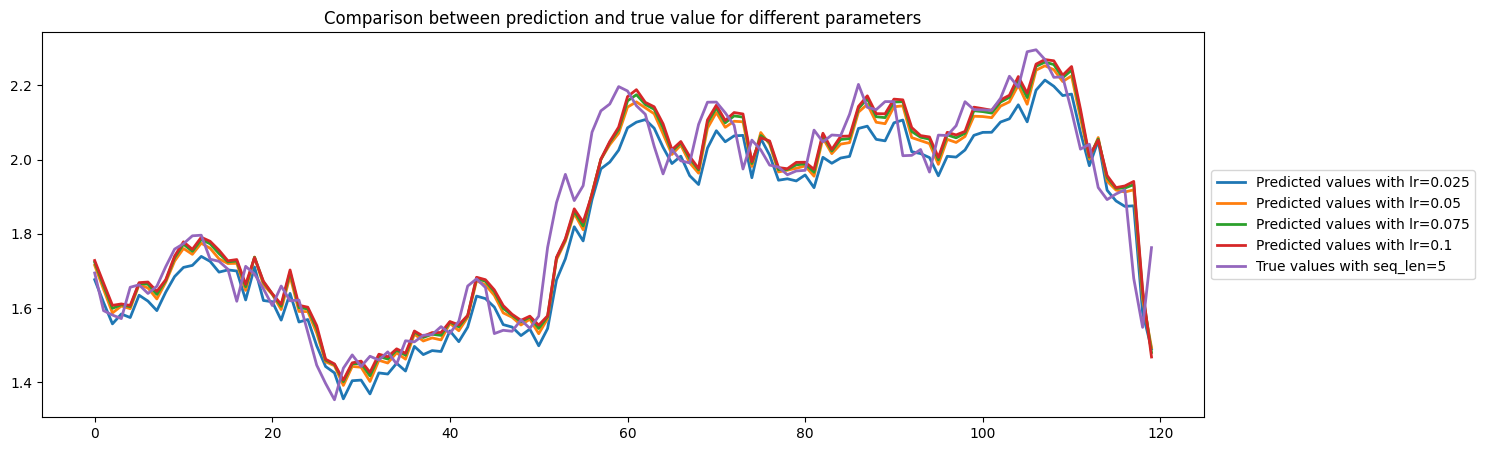

In [164]:
plt.figure(figsize=(15, 5))
for i, lr_val in enumerate(lrs):
  plt.plot(preds_GAN_arr[i], label=f"Predicted values with lr={lr_val}")
plt.plot(actuals_GAN_arr[0], label=f"True values with seq_len={seq_len}")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.title('Comparison between prediction and true value for different parameters')
plt.show()

### **Loss functions for comparison**

These are **loss functions** we use to understand how much our predictions deviate from the true data, and we specifically use these for consistency with the paper we are referencing.


1.   **Mean Absolute Error (MAE)**

  \begin{align}
  \text{MAE} = \frac{1}{N}\sum_{k=1}^{N} \lvert \hat{y}_k - y_k \rvert
  \end{align}

   - Measures the average absolute deviation between predictions and true values.
   - Useful when you want the “typical” prediction error.

2.   **Root Mean Squared Error (RMAE / RMSE)**

  \begin{align}
  \text{RMAE} = \sqrt{ \frac{1}{N} \sum_{{k=1}^{N}} (\hat{y}_k - y_k)^2 }
  \end{align}

  - Penalizes larger errors more heavily
  - Useful when large deviations are more critical than small ones.
  - Sensitive to outliers

3. **Relative MAE**

  \begin{align}
  \text{Relative MAE} = \frac{1}{N} \sum_{k=1}^{N} \frac{\lvert \hat{y}_k - y_k \rvert}{y_k}
  \end{align}

  - Measures error relative to the true value.
  - Useful when the data spans very different scales.

4. **Average Rise (AR)**

  \begin{align}
  \text{AR} = \frac{1}{N-1} \sum_{k=1}^{N-1} (y_{k+1} - y_k) \quad \text{if } \hat{y}_{k+1} > \hat{y}_k
  \end{align}

  - Captures the model’s ability to follow trends rather than exact values.  
  - Useful for time series or ordered data, focusing on correct increases.

In [148]:
def mae(y_true, y_pred):
    """
    Mean Absolute Error
    """
    return jnp.mean(jnp.abs(y_pred - y_true))

def rmae(y_true, y_pred):
    """
    Root Mean Squared Error
    """
    return jnp.sqrt(jnp.mean((y_pred - y_true)**2))

def relative_mae(y_true, y_pred):
    """
    Relative MAE
    """
    safe_y_true = jnp.where(y_true != 0, y_true, 1.0)
    return jnp.mean(jnp.abs(y_pred - y_true) / safe_y_true)

def ar(y_true, y_pred):
    """
    AR = 1/(N-1) * sum((y_{k+1} - y_k) if y_pred_{k+1} > y_pred_k)
    """
    diffs = y_true[1:] - y_true[:-1]
    mask = y_pred[1:] > y_pred[:-1]
    masked_diffs = diffs * mask
    count = jnp.sum(mask)
    return jnp.where(count > 0, jnp.sum(masked_diffs) / count, 0.0)

In [149]:
loss_functions = {
    "MAE": mae,
    "RMAE": rmae,
    "Relative MAE": relative_mae,
    "AR": ar
}

In [150]:
predictions_results = {'ANN': preds_ANN, 'SVR': preds_SVR, 'LSTM': preds_LSTM, 'LSTM_scratch': preds_LSTM_scratch, 'GAN': preds_GAN, 'GAN_scratch': preds_GAN_scratch}
actuals = {'ANN': actuals_ANN, 'SVR': actuals_SVR, 'LSTM': actuals_LSTM, 'LSTM_scratch': actuals_LSTM_scratch, 'GAN': actuals_GAN, 'GAN_scratch': actuals_GAN_scratch}

Here we create a function to evaluate the quality of the selected models based on various metrics.

In [157]:
def evaluate_losses(predictions_results, loss_funcs, actuals):
    """
    Evaluate multiple loss functions on multiple prediction arrays.

    Args:
        predictions_results (dict): keys = model names, values = arrays of predictions
        loss_funcs (dict): keys = loss names, values = functions(loss(y_true, y_pred))
        y_true (array-like): true values

    Returns:
        dict: nested dictionary {model_name: {loss_name: loss_value}}
    """
    results = {}

    for model_name, preds in predictions_results.items():
        y_true = jnp.array(actuals[model_name])  # prendo i "veri" corrispondenti a quel modello
        preds = jnp.array(preds)

        # nel caso abbiano lunghezze diverse, prendo la parte finale in comune
        min_len = min(len(preds), len(y_true))
        preds = preds[-min_len:]
        y_true = y_true[-min_len:]

        results[model_name] = {}
        for loss_name, loss_fn in loss_funcs.items():
            results[model_name][loss_name] = np.abs(float(loss_fn(y_true, preds)))

    return results

In [158]:
losses_results = evaluate_losses(predictions_results, loss_functions, actuals)

Here we display the results of the metrics, highlighting the best values.

In [159]:
def results_to_table(results):
    df = pd.DataFrame(results).T

    styled_df = df.style.highlight_min(axis=0, color='red').format("{:.4f}")
    return styled_df

In [160]:
results_to_table(losses_results)

,MAE,RMAE,Relative MAE,AR
ANN,0.1519,0.1862,0.0803,0.0064
SVR,0.0716,0.0912,0.0384,0.0032
LSTM,0.1229,0.1556,0.0635,0.0005
LSTM_scratch,0.1030,0.1285,0.0540,0.0021
GAN,0.0928,0.1160,0.0484,0.0017
GAN_scratch,0.0531,0.0736,0.0290,0.0006


### **Visual comparison between models**

In [161]:
def plot_predictions_comparison(models_predictions, actuals):

    fig, axes = plt.subplots(nrows=2, ncols=3, figsize = (18,12))
    axes = axes.flatten()
    colors = ["#E377C2", "#FF7F0E", "#2CA02C", "#D62728", "#9467BD","#9EDB3B"]

    for i, (model_name, preds) in enumerate(predictions_results.items()):
        acts = jnp.array(actuals[model_name])
        min_len = min(len(preds), len(acts))
        preds = preds[-min_len:]
        acts = acts[-min_len:]

        axes[i].set_title(f"{model_name} prediction")
        axes[i].plot(acts, label="True")
        axes[i].plot(preds, label="Predicted", color = colors[i])
        axes[i].legend()

    plt.tight_layout()
    fig.suptitle("Comparison between prediction and true value", fontsize=20, fontweight="bold", y=1.02)
    plt.show()


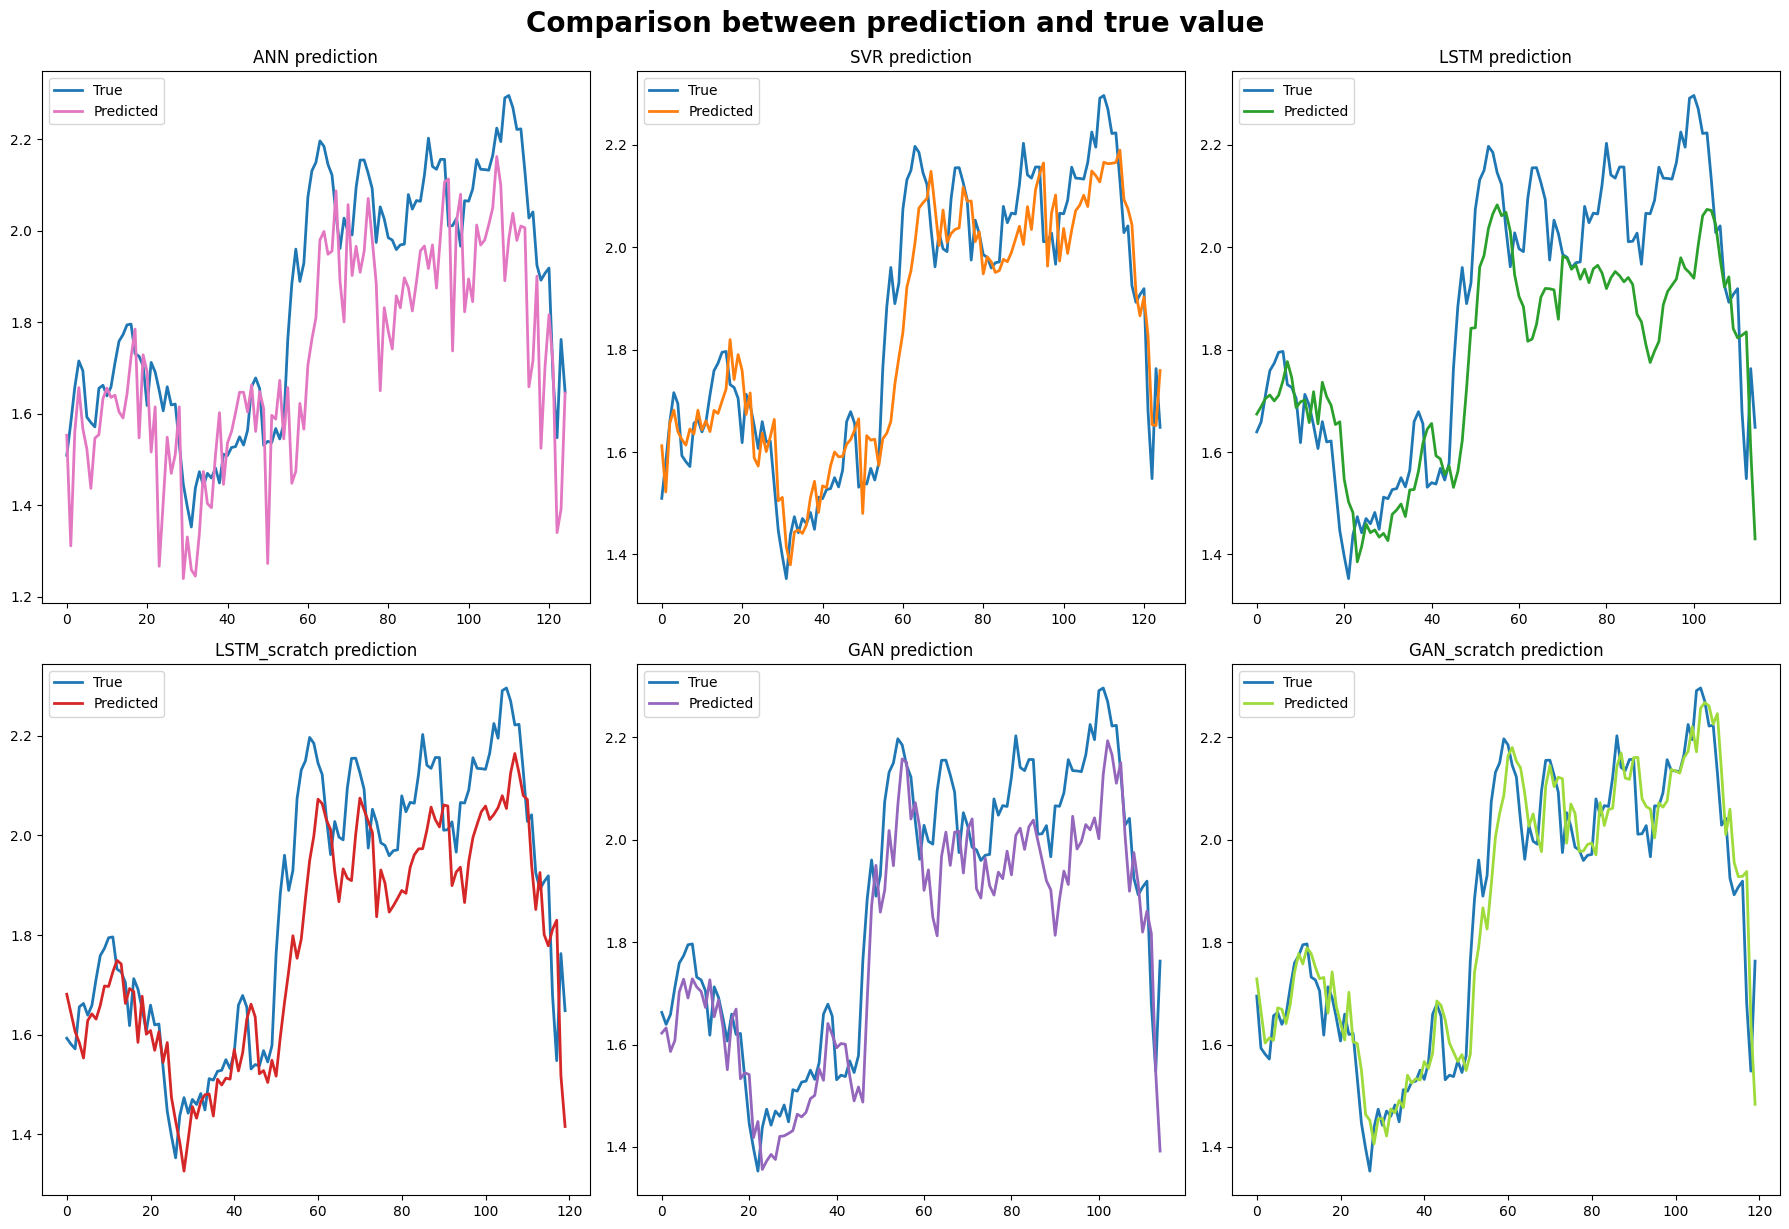

In [162]:
plot_predictions_comparison(predictions_results, actuals)